In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
!nvidia-smi

In [ ]:
import sys
import torch
import platform

print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))
    print(
        f"  Memory: "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024**3:.2f} GiB"
    )

In [ ]:
!pip install -q uv
!uv venv --python 3.12 --seed /kaggle/working/ckv-venv
!uv pip install --python /kaggle/working/ckv-venv/bin/python vllm --torch-backend=auto

In [ ]:
!/kaggle/working/ckv-venv/bin/python -c "import torch, vllm; print('PyTorch:', torch.__version__); print('CUDA:', torch.cuda.is_available()); print('vLLM:', vllm.__version__)"

In [ ]:
%%writefile /kaggle/working/test_vllm.py
import torch
from vllm import LLM, SamplingParams


def main():
    print("CUDA available:", torch.cuda.is_available())
    print("GPU:", torch.cuda.get_device_name(0))

    llm = LLM(
        model="Qwen/Qwen2.5-1.5B-Instruct",
        tensor_parallel_size=1,
        max_model_len=2048,
        gpu_memory_utilization=0.80,
        trust_remote_code=False,
    )

    sampling_params = SamplingParams(
        temperature=0.0,
        max_tokens=100,
    )

    prompts = [
        "Explain why tenant isolation matters in multi-tenant LLM inference.",
        "What is a KV cache in a transformer model?",
    ]

    outputs = llm.generate(prompts, sampling_params)

    for i, output in enumerate(outputs, 1):
        print(f"\n--- Response {i} ---")
        print(output.outputs[0].text)

    print("\nSUCCESS: vLLM inference completed.")


if __name__ == "__main__":
    main()

In [ ]:
!/kaggle/working/ckv-venv/bin/python /kaggle/working/test_vllm.py

In [ ]:
%cd /kaggle/working
!git clone https://github.com/aditya3275/conf-kv-1.git
%cd /kaggle/working/conf-kv-1
!git status --short
!ls -la

In [ ]:
%cd /kaggle/working/conf-kv-1

!cat README.md
!cat requirements.txt
!find app verifkv_service tests scripts configs -maxdepth 3 -type f


In [ ]:
!nvidia-smi

In [ ]:
%cd /kaggle/working/conf-kv-1

print("===== MAIN APPLICATION =====")
!sed -n '1,240p' app/main.py

print("\n===== SETTINGS =====")
!sed -n '1,240p' app/config/settings.py

print("\n===== BACKEND CONFIGURATION =====")
!cat configs/backends.yaml

print("\n===== ROOT FILES =====")
!find . -maxdepth 2 -type f \
  -not -path './.git/*' \
  | sort

In [ ]:
import os
import secrets

os.environ["VERIFKV_HMAC_SECRET"] = secrets.token_hex(32)

print("HMAC secret configured for this notebook session.")

In [ ]:
%cd /kaggle/working/conf-kv-1

!grep -nE "FastAPI|lifespan|startup|include_router|mount|OPA|VERIFKV|backend|health|ready" app/main.py
!grep -nE "BaseSettings|VERIFKV_HMAC_SECRET|OPA|VERIFKV|DATABASE|TIMEOUT" app/config/settings.py
!find . -maxdepth 3 -type f \
  \( -iname '*opa*' -o -iname '*.rego' -o -iname '*docker*' -o -iname '*compose*' \) \
  -not -path './.git/*' | sort

In [ ]:
%cd /kaggle/working/conf-kv-1

!cat requirements.txt

In [ ]:
!/kaggle/working/ckv-venv/bin/python -m pip install \
  "fastapi>=0.115,<1.0" \
  "uvicorn[standard]>=0.34,<1.0" \
  "pydantic>=2.10,<3.0" \
  "pydantic-settings>=2.7,<3.0" \
  "httpx>=0.28,<1.0" \
  "aiosqlite>=0.20,<1.0" \
  "PyYAML>=6.0,<7.0" \
  "python-dotenv>=1.0,<2.0"

In [ ]:
%cd /kaggle/working/conf-kv-1
!sed -n '1,240p' policies/rego/authz.rego

In [ ]:
!which opa || true
!opa version 2>/dev/null || true

In [ ]:
%cd /kaggle/working/conf-kv-1

!curl -fsSL \
  https://openpolicyagent.org/downloads/latest/opa_linux_amd64 \
  -o /kaggle/working/opa

!chmod +x /kaggle/working/opa
!/kaggle/working/opa version

In [ ]:
%cd /kaggle/working/conf-kv-1

!/kaggle/working/opa check policies/rego
!/kaggle/working/opa test policies/rego -v

In [ ]:
%cd /kaggle/working/conf-kv-1

from pathlib import Path

p = Path("policies/rego/authz.rego")
s = p.read_text()

old = "input.recommendation.zone not in input.tenant.allowed_zones"
new = "not (input.recommendation.zone in input.tenant.allowed_zones)"

assert s.count(old) == 1, "Expected exactly one invalid expression"
p.write_text(s.replace(old, new))

print("Fixed the invalid membership expression.")

In [ ]:
%cd /kaggle/working/conf-kv-1

!/kaggle/working/opa check policies/rego
!/kaggle/working/opa test policies/rego -v

In [ ]:
import subprocess
import time
import requests

opa_bin = "/kaggle/working/opa"
policy_dir = "/kaggle/working/conf-kv-1/policies/rego"

opa_log = open("/kaggle/working/opa.log", "w")

opa_process = subprocess.Popen(
    [
        opa_bin, "run",
        "--server",
        "--addr=127.0.0.1:8181",
        policy_dir,
    ],
    stdout=opa_log,
    stderr=subprocess.STDOUT,
)

for _ in range(20):
    try:
        response = requests.get(
            "http://127.0.0.1:8181/health",
            timeout=1,
        )
        if response.ok:
            print("OPA is running:", response.status_code)
            break
    except requests.RequestException:
        time.sleep(1)
else:
    print("OPA did not become healthy. Recent logs:")
    print(open("/kaggle/working/opa.log").read()[-4000:])

In [ ]:
%cd /kaggle/working/conf-kv-1

!sed -n '1,240p' verifkv_service/main.py
!sed -n '1,260p' verifkv_service/app.py
!sed -n '1,220p' app/main.py

In [ ]:
import os
import secrets
from pathlib import Path

PROJECT = Path("/kaggle/working/conf-kv-1")
DATA = PROJECT / "data"
DATA.mkdir(parents=True, exist_ok=True)

# Shared by the gateway and VerifKV in this notebook session.
if "VERIFKV_HMAC_SECRET" not in os.environ:
    os.environ["VERIFKV_HMAC_SECRET"] = secrets.token_hex(32)

os.environ["VERIFKV_URL"] = "http://127.0.0.1:8100"
os.environ["CONTROL_PLANE_DB_PATH"] = str(DATA / "control_plane.db")
os.environ["VERIFKV_DB_PATH"] = str(DATA / "verifkv.db")

print("Shared HMAC secret configured.")
print("Control-plane DB:", os.environ["CONTROL_PLANE_DB_PATH"])
print("VerifKV DB:", os.environ["VERIFKV_DB_PATH"])
print("VerifKV URL:", os.environ["VERIFKV_URL"])

In [ ]:
%cd /kaggle/working/conf-kv-1

!sed -n '1,240p' verifkv_service/app.py
!sed -n '1,200p' verifkv_service/main.py
!sed -n '1,240p' verifkv_service/store.py

In [ ]:
import os
import subprocess
import time
import requests

PROJECT = "/kaggle/working/conf-kv-1"
PYTHON = "/kaggle/working/ckv-venv/bin/python"

assert os.environ.get("VERIFKV_HMAC_SECRET"), (
    "Shared HMAC secret is missing. Recreate it before starting services."
)

# Set these before starting the service.
os.environ["VERIFKV_URL"] = "http://127.0.0.1:8100"
os.environ["VERIFKV_DB_PATH"] = f"{PROJECT}/data/verifkv.db"

# Stop an earlier service process if this cell was already run.
if "verifkv_process" in globals() and verifkv_process.poll() is None:
    verifkv_process.terminate()
    verifkv_process.wait(timeout=5)

verifkv_log = open("/kaggle/working/verifkv.log", "w")

verifkv_process = subprocess.Popen(
    [
        PYTHON, "-c",
        """
import os
import uvicorn
from verifkv_service.app import create_app

app = create_app(
    db_path=os.environ["VERIFKV_DB_PATH"],
    hmac_secret=os.environ["VERIFKV_HMAC_SECRET"],
)

uvicorn.run(app, host="127.0.0.1", port=8100, log_level="info")
""",
    ],
    cwd=PROJECT,
    env=os.environ.copy(),
    stdout=verifkv_log,
    stderr=subprocess.STDOUT,
)

for _ in range(20):
    try:
        response = requests.get(
            "http://127.0.0.1:8100/health",
            timeout=1,
        )
        if response.ok:
            print("VerifKV healthy:", response.json())
            break
    except requests.RequestException:
        time.sleep(1)
else:
    print("VerifKV failed to start. Logs:")
    print(open("/kaggle/working/verifkv.log").read()[-5000:])

In [ ]:
import requests

for name, url in [
    ("OPA", "http://127.0.0.1:8181/health"),
    ("VerifKV", "http://127.0.0.1:8100/health"),
]:
    try:
        r = requests.get(url, timeout=3)
        print(name, r.status_code, r.text[:300])
    except requests.RequestException as exc:
        print(name, "ERROR:", exc)

In [ ]:
%cd /kaggle/working/conf-kv-1

print("===== BACKEND REGISTRY SCRIPT =====")
!sed -n '1,240p' scripts/register_backend.py

print("\n===== BACKEND CONFIG =====")
!cat configs/backends.yaml

print("\n===== GATEWAY SETTINGS =====")
!sed -n '1,260p' app/config/settings.py

print("\n===== BACKEND REGISTRY =====")
!sed -n '1,280p' app/registry/backend_registry.py

print("\n===== ENFORCEMENT PROXY =====")
!sed -n '1,260p' app/enforcement/proxy.py

In [ ]:
import os
import subprocess
import time
import requests

PYTHON = "/kaggle/working/ckv-venv/bin/python"
MODEL = "Qwen/Qwen2.5-1.5B-Instruct"

# Start vLLM on a separate port from OPA and VerifKV.
if "vllm_api_process" in globals() and vllm_api_process.poll() is None:
    print("vLLM API server is already running.")
else:
    vllm_api_log = open("/kaggle/working/vllm_api.log", "w")

    vllm_api_process = subprocess.Popen(
        [
            PYTHON, "-m", "vllm.entrypoints.openai.api_server",
            "--model", MODEL,
            "--host", "127.0.0.1",
            "--port", "8001",
            "--max-model-len", "2048",
            "--gpu-memory-utilization", "0.70",
            "--tensor-parallel-size", "1",
        ],
        stdout=vllm_api_log,
        stderr=subprocess.STDOUT,
        cwd="/kaggle/working/conf-kv-1",
        env=os.environ.copy(),
    )

    print("Started vLLM API server; PID:", vllm_api_process.pid)

for _ in range(90):
    if vllm_api_process.poll() is not None:
        print("vLLM exited. Recent log:")
        print(open("/kaggle/working/vllm_api.log").read()[-6000:])
        break

    try:
        r = requests.get("http://127.0.0.1:8001/v1/models", timeout=2)
        if r.ok:
            print("vLLM API ready:", r.status_code)
            print(r.json())
            break
    except requests.RequestException:
        pass

    time.sleep(2)
else:
    print("vLLM is still starting. Recent log:")
    print(open("/kaggle/working/vllm_api.log").read()[-4000:])

In [ ]:
import requests

response = requests.post(
    "http://127.0.0.1:8001/v1/chat/completions",
    json={
        "model": "Qwen/Qwen2.5-1.5B-Instruct",
        "messages": [
            {
                "role": "user",
                "content": "Briefly explain tenant isolation in LLM inference."
            }
        ],
        "max_tokens": 80,
        "temperature": 0,
    },
    timeout=120,
)

print("HTTP status:", response.status_code)
print(response.text[:3000])
response.raise_for_status()

In [ ]:
%cd /kaggle/working/conf-kv-1

print("===== ZONE ENUM =====")
!grep -n -A35 -B5 "class Zone" app/models/enums.py

print("\n===== BACKEND REGISTRATION CLI =====")
!sed -n '1,220p' scripts/register_backend.py

print("\n===== TENANT CREATION CLI =====")
!sed -n '1,240p' scripts/create_tenant.py

In [ ]:
%cd /kaggle/working/conf-kv-1

print("===== BACKEND REGISTRATION ARGUMENTS =====")
!/kaggle/working/ckv-venv/bin/python scripts/register_backend.py --help

print("\n===== TENANT CREATION ARGUMENTS =====")
!/kaggle/working/ckv-venv/bin/python scripts/create_tenant.py --help

print("\n===== GATEWAY CONFIGURATION FIELDS =====")
!grep -nE "class Settings|opa_url|verifkv_url|control_plane_db_path|upstream_timeout|hmac|tenant|api_key" app/config/settings.py app/gateway/auth.py

In [ ]:
%cd /kaggle/working/conf-kv-1

!PYTHONPATH=/kaggle/working/conf-kv-1 /kaggle/working/ckv-venv/bin/python scripts/register_backend.py --help

!PYTHONPATH=/kaggle/working/conf-kv-1 /kaggle/working/ckv-venv/bin/python scripts/create_tenant.py --help

In [ ]:
%cd /kaggle/working/conf-kv-1

!PYTHONPATH=/kaggle/working/conf-kv-1 \
 /kaggle/working/ckv-venv/bin/python scripts/register_backend.py \
 --id kaggle-t4-general \
 --endpoint http://127.0.0.1:8001 \
 --zone general \
 --gpu 0 \
 --available

In [ ]:
%cd /kaggle/working/conf-kv-1

!PYTHONPATH=/kaggle/working/conf-kv-1 \
 /kaggle/working/ckv-venv/bin/python scripts/create_tenant.py \
 --id kaggle-standard-tenant \
 --security-level standard \
 --zones general \
 --quota 100

In [ ]:
%cd /kaggle/working/conf-kv-1

!sed -n '1,120p' app/config/settings.py
!sed -n '1,200p' app/main.py
!sed -n '1,130p' app/gateway/auth.py

In [ ]:
%cd /kaggle/working/conf-kv-1

!grep -nE "VerifKVStore|VerifKVClient|hmac_secret|db_path|health_monitor" app/main.py
!grep -nE "def __init__|hmac_secret|db_path|/v1/events|/v1/verify" app/verifkv/client.py app/verifkv/store.py

In [ ]:
%cd /kaggle/working/conf-kv-1

from pathlib import Path

sections = {
    "app/main.py": [(115, 175), (185, 210)],
    "app/verifkv/client.py": [(20, 75), (135, 175)],
    "app/config/settings.py": [(40, 90)],
}

for filename, ranges in sections.items():
    lines = Path(filename).read_text().splitlines()
    print(f"\n--- {filename} ---")
    for start, end in ranges:
        print(f"\nLines {start}-{end}:")
        for i in range(start, min(end, len(lines)) + 1):
            print(f"{i}: {lines[i-1]}")

In [ ]:
%cd /kaggle/working/conf-kv-1

import os
from pathlib import Path

assert os.environ.get("VERIFKV_HMAC_SECRET"), (
    "VERIFKV_HMAC_SECRET is missing. Restore the existing secret "
    "used by the VerifKV service before continuing."
)

os.environ["OPA_URL"] = "http://127.0.0.1:8181"
os.environ["VERIFKV_URL"] = "http://127.0.0.1:8100"
os.environ["CONTROL_PLANE_DB_PATH"] = str(
    Path("/kaggle/working/conf-kv-1/data/control_plane.db")
)
os.environ["VERIFKV_DB_PATH"] = str(
    Path("/kaggle/working/conf-kv-1/data/verifkv.db")
)

print("Gateway environment configured.")
print("OPA:", os.environ["OPA_URL"])
print("External VerifKV:", os.environ["VERIFKV_URL"])
print("HMAC secret present:", bool(os.environ.get("VERIFKV_HMAC_SECRET")))

In [ ]:
%cd /kaggle/working/conf-kv-1

!tail -n 35 app/main.py
!grep -nE '^(app|application)[[:space:]]*=|uvicorn.run|def create_app|async def lifespan' app/main.py

In [ ]:
%cd /kaggle/working/conf-kv-1

import os
import subprocess
from pathlib import Path

project = Path("/kaggle/working/conf-kv-1")
venv_python = "/kaggle/working/ckv-venv/bin/python"

gateway_env = os.environ.copy()
gateway_env["PYTHONPATH"] = str(project)
gateway_env["OPA_URL"] = "http://127.0.0.1:8181"
gateway_env["VERIFKV_URL"] = "http://127.0.0.1:8100"
gateway_env["CONTROL_PLANE_DB_PATH"] = str(project / "data/control_plane.db")
gateway_env["VERIFKV_DB_PATH"] = str(project / "data/verifkv.db")

assert gateway_env.get("VERIFKV_HMAC_SECRET"), "Missing HMAC secret"

gateway_log = open("/kaggle/working/gateway.log", "w")

gateway_process = subprocess.Popen(
    [
        venv_python, "-m", "uvicorn",
        "app.main:app",
        "--host", "127.0.0.1",
        "--port", "8000",
    ],
    cwd=str(project),
    env=gateway_env,
    stdout=gateway_log,
    stderr=subprocess.STDOUT,
)

print("Gateway process started; PID:", gateway_process.pid)

In [ ]:
import time
import requests

time.sleep(3)

try:
    response = requests.get("http://127.0.0.1:8000/health", timeout=5)
    print("HTTP status:", response.status_code)
    print("Response:", response.text[:1000])
except Exception as exc:
    print("Gateway health request failed:", type(exc).__name__)

if gateway_process.poll() is not None:
    print("\nGateway exited. Recent logs:")
    print(Path("/kaggle/working/gateway.log").read_text()[-5000:])

In [ ]:
import getpass
import requests

tenant_api_key = getpass.getpass("Enter the tenant API key: ")

In [ ]:
import json
import requests

payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [
        {"role": "user", "content": "Reply with exactly: ConfidentialKV test successful"}
    ],
    "max_tokens": 40,
    "temperature": 0
}

response = requests.post(
    "http://127.0.0.1:8000/v1/chat/completions",
    headers={
        "Authorization": f"Bearer {tenant_api_key}",
        "Content-Type": "application/json",
    },
    json=payload,
    timeout=90,
)

print("HTTP status:", response.status_code)
print("Request ID:", response.headers.get("X-Request-ID"))
print("Backend ID:", response.headers.get("X-Backend-ID"))

try:
    print(json.dumps(response.json(), indent=2)[:2500])
except ValueError:
    print(response.text[:1500])

In [ ]:
from pathlib import Path
import requests

print("Gateway process status:")
try:
    print("Poll:", gateway_process.poll())
except NameError:
    print("gateway_process variable is missing.")

print("\nGateway log (last 5000 characters):")
log_path = Path("/kaggle/working/gateway.log")
print(log_path.read_text()[-5000:] if log_path.exists() else "Log file not found.")

print("\nService checks:")
for name, url in [
    ("Gateway", "http://127.0.0.1:8000/health"),
    ("OPA", "http://127.0.0.1:8181/health"),
    ("VerifKV", "http://127.0.0.1:8100/health"),
    ("vLLM", "http://127.0.0.1:8001/v1/models"),
]:
    try:
        r = requests.get(url, timeout=4)
        print(f"{name}: HTTP {r.status_code}")
    except requests.RequestException as e:
        print(f"{name}: UNREACHABLE ({type(e).__name__})")

In [ ]:
import os
import subprocess
import requests
import time
from pathlib import Path

gateway_url = "http://127.0.0.1:8000"
project = Path("/kaggle/working/conf-kv-1")

try:
    r = requests.get(f"{gateway_url}/health", timeout=2)
    print("Gateway is already reachable:", r.status_code)
except requests.RequestException:
    env = os.environ.copy()
    env["PYTHONPATH"] = str(project)
    env["OPA_URL"] = "http://127.0.0.1:8181"
    env["VERIFKV_URL"] = "http://127.0.0.1:8100"
    env["CONTROL_PLANE_DB_PATH"] = str(project / "data/control_plane.db")
    env["VERIFKV_DB_PATH"] = str(project / "data/verifkv.db")

    assert env.get("VERIFKV_HMAC_SECRET"), (
        "HMAC secret missing from this kernel. Do not generate a new one yet."
    )

    gateway_log = open("/kaggle/working/gateway.log", "a")
    gateway_process = subprocess.Popen(
        [
            "/kaggle/working/ckv-venv/bin/python",
            "-m", "uvicorn", "app.main:app",
            "--host", "127.0.0.1", "--port", "8000",
        ],
        cwd=str(project),
        env=env,
        stdout=gateway_log,
        stderr=subprocess.STDOUT,
        start_new_session=True,
    )

    time.sleep(3)
    print("Gateway process status:", gateway_process.poll())

    try:
        r = requests.get(f"{gateway_url}/health", timeout=5)
        print("Gateway health:", r.status_code, r.text[:500])
    except requests.RequestException as e:
        print("Gateway still unreachable:", type(e).__name__)
        print(Path("/kaggle/working/gateway.log").read_text()[-3000:])

In [ ]:
import requests
import time

time.sleep(5)

try:
    r = requests.get("http://127.0.0.1:8000/health", timeout=5)
    print("Gateway after 5 seconds:", r.status_code)
except requests.RequestException as e:
    print("Gateway unreachable:", type(e).__name__)

In [ ]:
import requests
import json

assert "tenant_api_key" in globals(), (
    "API key isn't available in this kernel. Re-enter it privately first."
)

payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [
        {
            "role": "user",
            "content": "Reply with exactly: ConfidentialKV test successful"
        }
    ],
    "max_tokens": 40,
    "temperature": 0
}

try:
    response = requests.post(
        "http://127.0.0.1:8000/v1/chat/completions",
        headers={"Authorization": f"Bearer {tenant_api_key}"},
        json=payload,
        timeout=90,
    )

    print("HTTP status:", response.status_code)
    print("Request ID:", response.headers.get("X-Request-ID"))
    print("Backend ID:", response.headers.get("X-Backend-ID"))

    try:
        print(json.dumps(response.json(), indent=2)[:2000])
    except ValueError:
        print(response.text[:1000])

except requests.RequestException as e:
    print("Request failed:", type(e).__name__, str(e)[:500])

In [ ]:
import sqlite3
from pathlib import Path
import requests

db_path = "/kaggle/working/conf-kv-1/data/control_plane.db"

print("=== 1. BACKEND REGISTRY ===")
con = sqlite3.connect(db_path)
con.row_factory = sqlite3.Row

tables = [
    r["name"] for r in con.execute(
        "SELECT name FROM sqlite_master WHERE type='table'"
    )
]
print("Tables:", tables)

for table in tables:
    if "backend" in table.lower():
        print(f"\nTable: {table}")
        cols = con.execute(f'PRAGMA table_info("{table}")').fetchall()
        print("Columns:", [c["name"] for c in cols])
        rows = con.execute(f'SELECT * FROM "{table}" LIMIT 10').fetchall()
        for row in rows:
            print(dict(row))

con.close()

print("\n=== 2. SERVICE HEALTH ===")
for name, url in [
    ("vLLM", "http://127.0.0.1:8001/health"),
    ("OPA", "http://127.0.0.1:8181/health"),
    ("VerifKV", "http://127.0.0.1:8100/health"),
]:
    try:
        r = requests.get(url, timeout=4)
        print(f"{name}: HTTP {r.status_code} — {r.text[:200]}")
    except requests.RequestException as e:
        print(f"{name}: {type(e).__name__}")

print("\n=== 3. RECENT GATEWAY LOGS ===")
log_path = Path("/kaggle/working/gateway.log")
if log_path.exists():
    lines = log_path.read_text(errors="replace").splitlines()
    keywords = ("eligible", "backend", "scheduler", "health", "503", "ERROR", "WARNING")
    matches = [line for line in lines if any(k.lower() in line.lower() for k in keywords)]
    print("\n".join(matches[-35:]) or "No matching log lines.")
else:
    print("Gateway log not found.")

In [ ]:
import requests
import subprocess

services = {
    "Gateway": "http://127.0.0.1:8000/health",
    "vLLM": "http://127.0.0.1:8001/health",
    "OPA": "http://127.0.0.1:8181/health",
    "VerifKV": "http://127.0.0.1:8100/health",
}

print("=== HTTP checks ===")
for name, url in services.items():
    try:
        r = requests.get(url, timeout=3)
        print(f"{name}: HTTP {r.status_code}")
    except requests.RequestException:
        print(f"{name}: UNREACHABLE")

print("\n=== Saved process handles ===")
for name in ["gateway_process", "vllm_api_process", "opa_process", "verifkv_process"]:
    proc = globals().get(name)
    if proc is None:
        print(f"{name}: no handle in this notebook kernel")
    else:
        print(f"{name}: {'running' if proc.poll() is None else 'exited'}")

In [ ]:
import subprocess
import requests
import time
from pathlib import Path

opa_log = open("/kaggle/working/opa.log", "a")

opa_process = subprocess.Popen(
    [
        "/kaggle/working/opa",
        "run",
        "--server",
        "--addr=127.0.0.1:8181",
        "/kaggle/working/conf-kv-1/policies/rego",
    ],
    stdout=opa_log,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

for _ in range(10):
    try:
        r = requests.get("http://127.0.0.1:8181/health", timeout=2)
        if r.status_code == 200:
            print("OPA is back: HTTP", r.status_code)
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    print("OPA did not become healthy. Recent log:")
    print(Path("/kaggle/working/opa.log").read_text()[-3000:])

In [ ]:
import os
import subprocess
import requests
import time
from pathlib import Path

project = Path("/kaggle/working/conf-kv-1")

assert os.environ.get("VERIFKV_HMAC_SECRET"), (
    "The existing HMAC secret is missing. Stop here; don't generate a new one."
)

verifkv_env = os.environ.copy()
verifkv_env["VERIFKV_DB_PATH"] = str(project / "data/verifkv.db")

verifkv_log = open("/kaggle/working/verifkv.log", "a")

verifkv_process = subprocess.Popen(
    [
        "/kaggle/working/ckv-venv/bin/python",
        "-c",
        (
            "import os, uvicorn; "
            "from verifkv_service.app import create_app; "
            "uvicorn.run(create_app("
            "db_path=os.environ['VERIFKV_DB_PATH'], "
            "hmac_secret=os.environ['VERIFKV_HMAC_SECRET']), "
            "host='127.0.0.1', port=8100)"
        ),
    ],
    cwd=str(project),
    env=verifkv_env,
    stdout=verifkv_log,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

for _ in range(15):
    try:
        r = requests.get("http://127.0.0.1:8100/health", timeout=2)
        if r.status_code == 200:
            print("VerifKV is back: HTTP", r.status_code, r.text[:200])
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    print("VerifKV did not become healthy. Recent log:")
    print(Path("/kaggle/working/verifkv.log").read_text()[-3000:])

In [ ]:
import subprocess
import requests
import time
from pathlib import Path

vllm_log = open("/kaggle/working/vllm.log", "a")

vllm_api_process = subprocess.Popen(
    [
        "/kaggle/working/ckv-venv/bin/python",
        "-m", "vllm.entrypoints.openai.api_server",
        "--model", "Qwen/Qwen2.5-1.5B-Instruct",
        "--host", "127.0.0.1",
        "--port", "8001",
        "--max-model-len", "2048",
        "--gpu-memory-utilization", "0.70",
        "--tensor-parallel-size", "1",
    ],
    stdout=vllm_log,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

print("vLLM process started. Waiting for model loading...")

for attempt in range(60):
    if vllm_api_process.poll() is not None:
        print("vLLM exited during startup.")
        break

    try:
        r = requests.get("http://127.0.0.1:8001/v1/models", timeout=3)
        if r.status_code == 200:
            print("vLLM is ready: HTTP 200")
            print(r.json())
            break
    except requests.RequestException:
        pass

    time.sleep(5)
else:
    print("vLLM did not become ready within five minutes.")

if vllm_api_process.poll() is not None:
    print("\nRecent vLLM logs:")
    print(Path("/kaggle/working/vllm.log").read_text()[-5000:])

In [ ]:
import requests

for name, url in [
    ("Gateway", "http://127.0.0.1:8000/health"),
    ("OPA", "http://127.0.0.1:8181/health"),
    ("VerifKV", "http://127.0.0.1:8100/health"),
    ("vLLM", "http://127.0.0.1:8001/v1/models"),
]:
    try:
        r = requests.get(url, timeout=5)
        print(f"{name}: HTTP {r.status_code}")
    except requests.RequestException as e:
        print(f"{name}: UNREACHABLE ({type(e).__name__})")

In [ ]:
import requests
import json

assert "tenant_api_key" in globals(), (
    "API key isn't available. Re-enter it privately using getpass."
)

payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [
        {
            "role": "user",
            "content": "Reply with exactly: ConfidentialKV test successful"
        }
    ],
    "max_tokens": 40,
    "temperature": 0
}

try:
    response = requests.post(
        "http://127.0.0.1:8000/v1/chat/completions",
        headers={"Authorization": f"Bearer {tenant_api_key}"},
        json=payload,
        timeout=90,
    )

    print("HTTP status:", response.status_code)
    print("Request ID:", response.headers.get("X-Request-ID"))
    print("Backend ID:", response.headers.get("X-Backend-ID"))

    try:
        print(json.dumps(response.json(), indent=2)[:2000])
    except ValueError:
        print(response.text[:1000])

except requests.RequestException as e:
    print("Request failed:", type(e).__name__, str(e)[:300])

In [ ]:
import requests

url = "http://127.0.0.1:8100/v1/verify"

try:
    r = requests.get(url, timeout=10)
    print("HTTP status:", r.status_code)
    print("Response:", r.text[:2500])
except requests.RequestException as e:
    print("Verification request failed:", type(e).__name__)

In [ ]:
import requests
import json

r = requests.get("http://127.0.0.1:8100/v1/verify", timeout=10)

print("HTTP status:", r.status_code)

try:
    result = r.json()
    print(json.dumps(result, indent=2)[:3000])
except ValueError:
    print(r.text[:2000])

In [ ]:
%cd /kaggle/working/conf-kv-1

from pathlib import Path
import sqlite3

print("=== VERIFIER LOGIC ===")
p = Path("verifkv_service/store.py")
lines = p.read_text().splitlines()

terms = ("chain_link_mismatch", "previous_hash", "prev_hash", "genesis")
hits = [i for i, line in enumerate(lines) if any(t in line.lower() for t in terms)]

for i in hits[:4]:
    start, end = max(0, i-2), min(len(lines), i+3)
    print(f"\nLines {start+1}-{end}:")
    for j in range(start, end):
        print(f"{j+1}: {lines[j]}")

print("\n=== VERIFKV DATABASE SCHEMA ===")
db = Path("data/verifkv.db")
if db.exists():
    con = sqlite3.connect(str(db))
    tables = con.execute(
        "SELECT name FROM sqlite_master WHERE type='table'"
    ).fetchall()
    for (table,) in tables:
        cols = con.execute(f'PRAGMA table_info("{table}")').fetchall()
        print(table, "=>", [c[1] for c in cols])
    con.close()
else:
    print("Database not found.")

In [ ]:
%cd /kaggle/working/conf-kv-1

import sqlite3
from pathlib import Path

# Inspect the first event's chain metadata only.
con = sqlite3.connect("data/verifkv.db")
con.row_factory = sqlite3.Row

row = con.execute("""
    SELECT sequence_number, event_type, previous_hash, event_hash
    FROM verifkv_events
    ORDER BY sequence_number
    LIMIT 1
""").fetchone()

print("=== FIRST EVENT ===")
print(dict(row) if row else "No events found")

con.close()

# Inspect the verifier and event hash implementation.
p = Path("verifkv_service/store.py")
lines = p.read_text().splitlines()

print("\n=== HASH / VERIFICATION METHODS ===")
for start, end in [(130, 190), (550, 630)]:
    print(f"\nLines {start}-{end}:")
    for i in range(start - 1, min(end, len(lines))):
        line = lines[i]
        if any(term in line.lower() for term in (
            "def ", "previous_hash", "event_hash", "sha256",
            "canonical", "genesis", "valid", "mismatch",
        )):
            print(f"{i+1}: {line}")

In [ ]:
%cd /kaggle/working/conf-kv-1

from pathlib import Path

for filename in [
    "verifkv_service/store.py",
    "app/verifkv/store.py",
]:
    p = Path(filename)
    if not p.exists():
        continue

    lines = p.read_text().splitlines()
    print(f"\n--- {filename} ---")

    for i, line in enumerate(lines):
        if any(term in line.lower() for term in (
            "def verify", "def _canonicalize_event",
            "def _get_previous_hash", "chain_link_mismatch",
        )):
            start, end = max(0, i-2), min(len(lines), i+22)
            print(f"\nLines {start+1}-{end}:")
            for j in range(start, end):
                print(f"{j+1}: {lines[j]}")

In [ ]:
%cd /kaggle/working/conf-kv-1

from pathlib import Path

p = Path("verifkv_service/store.py")
lines = p.read_text().splitlines()

# Print only the relevant sections.
for start, end in [(180, 215), (275, 300), (315, 350)]:
    print(f"\n--- Lines {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")

In [ ]:
%cd /kaggle/working/conf-kv-1
!git pull --ff-only

In [ ]:
%cd /kaggle/working/conf-kv-1

!grep -n -A 8 -B 3 'def _get_previous_hash\|def verify_chain' verifkv_service/store.py

In [ ]:
import requests

for name, url in {
    "Gateway": "http://127.0.0.1:8000/health",
    "OPA": "http://127.0.0.1:8181/health",
    "VerifKV": "http://127.0.0.1:8100/health",
    "vLLM": "http://127.0.0.1:8001/v1/models",
}.items():
    try:
        r = requests.get(url, timeout=3)
        print(f"{name}: HTTP {r.status_code}")
    except requests.RequestException:
        print(f"{name}: NOT REACHABLE")

In [ ]:
%cd /kaggle/working/conf-kv-1

!grep -n -A 35 -B 5 'def __init__\|def append\|def verify_chain\|def _get_previous_hash' verifkv_service/store.py

In [ ]:
%cd /kaggle/working/conf-kv-1

!grep -n -E 'def __init__|def append|def verify_chain|def _get_previous_hash|GENESIS_HASH|previous_hash = ' verifkv_service/store.py

In [ ]:
%cd /kaggle/working/conf-kv-1

with open("verifkv_service/store.py") as f:
    lines = f.readlines()

for start, end in [(35, 75), (185, 245), (250, 310)]:
    print(f"\n--- Lines {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}", end="")

In [ ]:
%cd /kaggle/working/conf-kv-1

import tempfile
from pathlib import Path

from app.models.verifkv import GENESIS_HASH, VerifKVEvent
from verifkv_service.store import VerifKVStore

test_dir = tempfile.TemporaryDirectory(prefix="verifkv_test_")
test_db = str(Path(test_dir.name) / "fresh_test.db")

# Use a test-only secret; do not print it.
test_store = VerifKVStore(
    db_path=test_db,
    hmac_secret="temporary-test-secret-only",
)

print("Empty chain:", test_store.verify_chain())

In [ ]:
import inspect
from app.models.verifkv import VerifKVEvent

print(inspect.signature(VerifKVEvent))

In [ ]:
from app.models.verifkv import VerifKVEvent, VerifKVEventType, GENESIS_HASH

event = VerifKVEvent(
    event_type=next(iter(VerifKVEventType)),
    source="kaggle-fresh-chain-test",
    tenant_id="test-tenant",
    request_id="test-request-001",
    payload={"test": True, "purpose": "genesis-hash-validation"},
)

sequence = test_store.append(event)
result = test_store.verify_chain()

print("Sequence:", sequence)
print("Expected genesis:", GENESIS_HASH)
print("Verification:", result)

In [ ]:
import requests

url = "http://127.0.0.1:8100/v1/verify"

try:
    r = requests.get(url, timeout=10)
    print("HTTP:", r.status_code)
    print("Result:", r.json())
except Exception as e:
    print(type(e).__name__, str(e))

In [ ]:
r = requests.get("http://127.0.0.1:8100/v1/verify", timeout=10)

print("HTTP:", r.status_code)
print("Verification:", r.json())

In [ ]:
import requests

r = requests.get(
    "http://127.0.0.1:8100/v1/verify",
    timeout=10
)

print(r.json())

In [ ]:
%cd /kaggle/working/conf-kv-1

!grep -n -E 'GENESIS_HASH|return "GENESIS"|previous_hash = ' verifkv_service/store.py

In [ ]:
import sqlite3

db_path = "/kaggle/working/conf-kv-1/data/verifkv.db"

conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)

row = conn.execute("""
    SELECT sequence_number, previous_hash, event_hash
    FROM verifkv_events
    ORDER BY sequence_number ASC
    LIMIT 1
""").fetchone()

print("First event:", row)
print("Expected genesis:", GENESIS_HASH)

conn.close()

In [ ]:
from app.models.verifkv import GENESIS_HASH

In [ ]:
import sqlite3

db_path = "/kaggle/working/conf-kv-1/data/verifkv.db"

conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)

row = conn.execute("""
    SELECT sequence_number, previous_hash, event_hash
    FROM verifkv_events
    ORDER BY sequence_number ASC
    LIMIT 1
""").fetchone()

print("First event:", row)
print("Expected genesis:", GENESIS_HASH)

conn.close()

In [ ]:
import os

print("Configured DB:", os.environ.get("VERIFKV_DB_PATH"))
print("Configured service URL:", os.environ.get("VERIFKV_URL"))

In [ ]:
%cd /kaggle/working/conf-kv-1

!sed -n '258,300p' verifkv_service/store.py
!grep -n -E 'VERIFKV_DB_PATH|create_app|VerifKVStore\(' verifkv_service/app.py

In [ ]:
import requests

r = requests.get(
    "http://127.0.0.1:8100/v1/verify",
    timeout=10
)

print("HTTP:", r.status_code)
print("Result:", r.json())

In [ ]:
%cd /kaggle/working/conf-kv-1

!sed -n '1,65p' verifkv_service/app.py

In [ ]:
import os
import requests

print("Notebook DB path:", os.environ.get("VERIFKV_DB_PATH"))
print("Notebook HMAC secret configured:",
      bool(os.environ.get("VERIFKV_HMAC_SECRET")))

!ps -eo pid,args | grep '[u]vicorn'

In [ ]:
import os
import sqlite3

db_path = os.path.realpath(os.environ["VERIFKV_DB_PATH"])

print("Resolved DB:", db_path)
print("DB exists:", os.path.exists(db_path))
print("DB size:", os.path.getsize(db_path) if os.path.exists(db_path) else None)

conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)

row = conn.execute("""
    SELECT sequence_number, previous_hash, event_hash
    FROM verifkv_events
    ORDER BY sequence_number
    LIMIT 1
""").fetchone()

print("First row:", row)
conn.close()

In [ ]:
import os

print("Service working directory:",
      os.readlink("/proc/875/cwd"))
print("Service command line:",
      open("/proc/875/cmdline", "rb").read().replace(b"\0", b" ").decode())

In [ ]:
import requests

# Ask the live service to verify its chain again
r = requests.get("http://127.0.0.1:8100/v1/verify", timeout=10)
print("Live verification:", r.json())

# Show the source code currently on disk around the genesis check
%cd /kaggle/working/conf-kv-1
!sed -n '135,155p' verifkv_service/store.py
!sed -n '275,295p' verifkv_service/store.py

In [ ]:
import os
import sys

print("Python executable:", os.readlink("/proc/875/exe"))
print("Service PID:", 875)
print("Module file on disk:",
      "/kaggle/working/conf-kv-1/verifkv_service/store.py")

In [ ]:
import os
import signal
import subprocess
import time
import requests

# Preserve the existing environment, database path, and HMAC secret.
assert os.environ.get("VERIFKV_DB_PATH"), "VERIFKV_DB_PATH is missing"
assert os.environ.get("VERIFKV_HMAC_SECRET"), "HMAC secret is missing"

# Stop only the external VerifKV process.
try:
    os.kill(875, signal.SIGTERM)
except ProcessLookupError:
    pass

time.sleep(2)

# Start VerifKV using the updated source code.
log_file = open("/kaggle/working/verifkv-restart.log", "a")

verifkv_process = subprocess.Popen(
    [
        "/kaggle/working/ckv-venv/bin/python",
        "-c",
        (
            "import os, uvicorn; "
            "from verifkv_service.app import create_app; "
            "uvicorn.run("
            "create_app("
            "db_path=os.environ['VERIFKV_DB_PATH'], "
            "hmac_secret=os.environ['VERIFKV_HMAC_SECRET']"
            "), "
            "host='127.0.0.1', port=8100)"
        ),
    ],
    cwd="/kaggle/working/conf-kv-1",
    env=os.environ.copy(),
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

print("New VerifKV PID:", verifkv_process.pid)

In [ ]:
import requests
import time

for attempt in range(15):
    try:
        health = requests.get(
            "http://127.0.0.1:8100/health", timeout=2
        )
        if health.status_code == 200:
            break
    except requests.RequestException:
        pass
    time.sleep(1)

r = requests.get("http://127.0.0.1:8100/v1/verify", timeout=10)
print("HTTP:", r.status_code)
print("Verification:", r.json())

In [ ]:
import sqlite3
import hashlib
import json
import os

from app.models.verifkv import GENESIS_HASH

db_path = os.environ["VERIFKV_DB_PATH"]
conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
conn.row_factory = sqlite3.Row

row = conn.execute("""
    SELECT sequence_number, payload_json, previous_hash, event_hash
    FROM verifkv_events
    ORDER BY sequence_number
    LIMIT 1
""").fetchone()

conn.close()

canonical_json = row["payload_json"]
recomputed_hash = hashlib.sha256(
    (GENESIS_HASH + canonical_json).encode("utf-8")
).hexdigest()

print("Stored previous hash matches genesis:", row["previous_hash"] == GENESIS_HASH)
print("Stored event hash:", row["event_hash"])
print("Recomputed event hash:", recomputed_hash)
print("Hashes match:", row["event_hash"] == recomputed_hash)
print("Stored payload length:", len(canonical_json))

In [ ]:
import sqlite3
import os

db_path = os.environ["VERIFKV_DB_PATH"]
conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
conn.row_factory = sqlite3.Row

row = conn.execute("""
    SELECT payload_json, previous_hash, event_hash, hmac_tag
    FROM verifkv_events
    ORDER BY sequence_number
    LIMIT 1
""").fetchone()

print("Stored payload:")
print(row["payload_json"])
print("\nStored previous hash:", row["previous_hash"])
print("Stored event hash:", row["event_hash"])
print("HMAC present:", bool(row["hmac_tag"]))

conn.close()

In [ ]:
%cd /kaggle/working/conf-kv-1

!sed -n '195,220p' verifkv_service/store.py
!sed -n '300,345p' verifkv_service/store.py
!sed -n '500,545p' app/verifkv/store.py

In [ ]:
%cd /kaggle/working/conf-kv-1

!sed -n '520,590p' app/verifkv/store.py

In [ ]:
%cd /kaggle/working/conf-kv-1

!grep -n -E 'def append|canonical_event|canonical_json|event_hash =|hash_input =' app/verifkv/store.py | head -25

In [ ]:
%cd /kaggle/working/conf-kv-1

!sed -n '350,410p' app/verifkv/store.py

In [ ]:
!grep -n -E 'VerifKVEvent|/v1/events|event_hash|payload_json' app/verifkv/client.py verifkv_service/app.py

In [ ]:
%cd /kaggle/working/conf-kv-1

!sed -n '130,175p' app/verifkv/client.py
!sed -n '90,120p' verifkv_service/app.py

In [ ]:
%cd /kaggle/working/conf-kv-1
!sed -n '218,250p' verifkv_service/store.py

In [ ]:
import requests

services = {
    "vLLM": "http://127.0.0.1:8001/v1/models",
    "Gateway": "http://127.0.0.1:8000/health",
    "OPA": "http://127.0.0.1:8181/health",
    "VerifKV": "http://127.0.0.1:8100/health",
}

for name, url in services.items():
    try:
        response = requests.get(url, timeout=3)
        print(f"{name}: HTTP {response.status_code}")
    except requests.RequestException:
        print(f"{name}: NOT REACHABLE")

In [ ]:
import requests
import time
import statistics

VLLM_URL = "http://127.0.0.1:8001/v1/chat/completions"
MODEL = "Qwen/Qwen2.5-1.5B-Instruct"

payload = {
    "model": MODEL,
    "messages": [
        {"role": "user", "content": "Explain cloud computing in exactly 50 words."}
    ],
    "max_tokens": 80,
    "temperature": 0,
}

# Warm-up request; exclude it from measurements.
warmup = requests.post(VLLM_URL, json=payload, timeout=90)
warmup.raise_for_status()
print("Warm-up: HTTP", warmup.status_code)

latencies = []
for i in range(10):
    start = time.perf_counter()
    response = requests.post(VLLM_URL, json=payload, timeout=90)
    elapsed = time.perf_counter() - start
    response.raise_for_status()
    latencies.append(elapsed)

    print(f"Run {i+1:02d}: {elapsed:.3f}s")

print("\n--- Direct vLLM baseline ---")
print(f"Successful requests: {len(latencies)}/10")
print(f"Mean latency:   {statistics.mean(latencies):.3f}s")
print(f"Median latency: {statistics.median(latencies):.3f}s")
print(f"Min latency:    {min(latencies):.3f}s")
print(f"Max latency:    {max(latencies):.3f}s")

In [ ]:
import requests
import time
import statistics

GATEWAY_URL = "http://127.0.0.1:8000/v1/chat/completions"

headers = {
    "Authorization": f"Bearer {tenant_api_key}",
    "Content-Type": "application/json",
}

payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [
        {
            "role": "user",
            "content": "Explain cloud computing in exactly 50 words."
        }
    ],
    "max_tokens": 80,
    "temperature": 0,
}

# Warm-up: exclude from measurements.
warmup = requests.post(
    GATEWAY_URL, headers=headers, json=payload, timeout=90
)
print("Warm-up HTTP:", warmup.status_code)

if warmup.status_code != 200:
    print(warmup.text[:500])
    raise RuntimeError("Gateway warm-up failed; fix this before benchmarking.")

latencies = []

for i in range(10):
    start = time.perf_counter()
    response = requests.post(
        GATEWAY_URL, headers=headers, json=payload, timeout=90
    )
    elapsed = time.perf_counter() - start

    if response.status_code != 200:
        print(f"Run {i+1:02d}: HTTP {response.status_code}")
        print(response.text[:300])
        continue

    latencies.append(elapsed)
    print(f"Run {i+1:02d}: {elapsed:.3f}s")

if latencies:
    print("\n--- ConfidentialKV gateway results ---")
    print(f"Successful requests: {len(latencies)}/10")
    print(f"Mean latency:   {statistics.mean(latencies):.3f}s")
    print(f"Median latency: {statistics.median(latencies):.3f}s")
    print(f"Min latency:    {min(latencies):.3f}s")
    print(f"Max latency:    {max(latencies):.3f}s")

In [ ]:
import requests
import time
import statistics

DIRECT = "http://127.0.0.1:8001/v1/chat/completions"
GATEWAY = "http://127.0.0.1:8000/v1/chat/completions"

headers = {
    "Authorization": f"Bearer {tenant_api_key}",
    "Content-Type": "application/json",
}

payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [
        {"role": "user",
         "content": "Explain cloud computing in exactly 50 words."}
    ],
    "max_tokens": 80,
    "temperature": 0,
}

def timed_request(url, use_auth=False):
    start = time.perf_counter()
    r = requests.post(
        url,
        headers=headers if use_auth else None,
        json=payload,
        timeout=90,
    )
    elapsed = time.perf_counter() - start
    r.raise_for_status()
    return elapsed

# Warm both paths, excluding warm-ups from the data.
timed_request(DIRECT)
timed_request(GATEWAY, use_auth=True)

direct, gateway = [], []

for i in range(20):
    # Alternate request order to reduce order effects.
    order = (
        [(DIRECT, False, direct), (GATEWAY, True, gateway)]
        if i % 2 == 0
        else [(GATEWAY, True, gateway), (DIRECT, False, direct)]
    )

    for url, auth, results in order:
        results.append(timed_request(url, use_auth=auth))

print("Direct mean:", round(statistics.mean(direct), 3), "s")
print("Direct median:", round(statistics.median(direct), 3), "s")
print("Gateway mean:", round(statistics.mean(gateway), 3), "s")
print("Gateway median:", round(statistics.median(gateway), 3), "s")
print("Direct successes:", len(direct), "/ 20")
print("Gateway successes:", len(gateway), "/ 20")

In [ ]:
import requests
import time
import statistics

DIRECT = "http://127.0.0.1:8001/v1/chat/completions"
GATEWAY = "http://127.0.0.1:8000/v1/chat/completions"

headers = {
    "Authorization": f"Bearer {tenant_api_key}",
    "Content-Type": "application/json",
}

payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [
        {
            "role": "user",
            "content": (
                "Explain cloud computing, its architecture, "
                "deployment models, security challenges, and "
                "practical applications in detail."
            ),
        }
    ],
    "max_tokens": 128,
    "temperature": 0,
}

def measure(url, auth=False):
    start = time.perf_counter()
    r = requests.post(
        url,
        headers=headers if auth else None,
        json=payload,
        timeout=90,
    )
    elapsed = time.perf_counter() - start
    r.raise_for_status()

    data = r.json()
    usage = data.get("usage", {})
    tokens = usage.get("completion_tokens")

    if tokens is None:
        raise RuntimeError(
            "API did not return completion_tokens; "
            "cannot calculate reliable token throughput."
        )

    return elapsed, tokens, tokens / elapsed

# Warm-up both paths.
measure(DIRECT)
measure(GATEWAY, auth=True)

results = {"Direct": [], "Gateway": []}

for i in range(10):
    order = (
        [("Direct", DIRECT, False), ("Gateway", GATEWAY, True)]
        if i % 2 == 0
        else [("Gateway", GATEWAY, True), ("Direct", DIRECT, False)]
    )

    for name, url, auth in order:
        elapsed, tokens, rate = measure(url, auth)
        results[name].append((elapsed, tokens, rate))
        print(
            f"Pair {i+1:02d} | {name}: "
            f"{elapsed:.3f}s, {tokens} tokens, {rate:.2f} tokens/s"
        )

for name, rows in results.items():
    print(f"\n--- {name} ---")
    print("Mean latency:", round(statistics.mean(x[0] for x in rows), 3), "s")
    print("Mean output tokens:", round(statistics.mean(x[1] for x in rows), 1))
    print("Mean per-request token rate:", round(statistics.mean(x[2] for x in rows), 2), "tokens/s")

In [ ]:
import requests

url = "http://127.0.0.1:8000/v1/chat/completions"

headers = {
    "Authorization": f"Bearer {tenant_api_key}",
    "Content-Type": "application/json",
}

payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [
        {
            "role": "user",
            "content": "Explain cloud computing in detail."
        }
    ],
    "max_tokens": 128,
    "temperature": 0,
}

r = requests.post(url, headers=headers, json=payload, timeout=90)

print("HTTP status:", r.status_code)
print("Content-Type:", r.headers.get("Content-Type"))
print("Response body:", repr(r.text[:1000]))

In [ ]:

import requests
import time
import statistics
import json

DIRECT = "http://127.0.0.1:8001/v1/chat/completions"
GATEWAY = "http://127.0.0.1:8000/v1/chat/completions"

headers = {
    "Authorization": f"Bearer {tenant_api_key}",
    "Content-Type": "application/json",
}

payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [{
        "role": "user",
        "content": (
            "Explain cloud computing, its architecture, deployment "
            "models, security challenges, and practical applications in detail."
        )
    }],
    "max_tokens": 128,
    "temperature": 0,
}

def measure(url, auth=False):
    request_headers = headers if auth else {
        "Content-Type": "application/json"
    }

    start = time.perf_counter()
    r = requests.post(
        url, headers=request_headers, json=payload,
        timeout=120, stream=True
    )

    try:
        r.raise_for_status()
        content_type = r.headers.get("Content-Type", "")
        token_count = 0
        text_parts = []
        usage_tokens = None

        if "text/event-stream" in content_type:
            for line in r.iter_lines(decode_unicode=True):
                if not line or not line.startswith("data:"):
                    continue

                data = line[5:].strip()
                if data == "[DONE]":
                    break

                try:
                    chunk = json.loads(data)
                except json.JSONDecodeError:
                    continue

                usage = chunk.get("usage") or {}
                if usage.get("completion_tokens") is not None:
                    usage_tokens = usage["completion_tokens"]

                for choice in chunk.get("choices", []):
                    text = choice.get("delta", {}).get("content", "")
                    if text:
                        text_parts.append(text)
        else:
            data = r.json()
            usage_tokens = (data.get("usage") or {}).get("completion_tokens")
            text_parts = [
                choice.get("message", {}).get("content", "")
                for choice in data.get("choices", [])
            ]

        elapsed = time.perf_counter() - start
        generated_text = "".join(text_parts)

        if usage_tokens is not None:
            token_count = usage_tokens
        elif generated_text:
            # Approximation only; characters/4 is NOT an exact token count.
            token_count = None
        else:
            raise RuntimeError(
                f"No generated text or token usage. "
                f"HTTP {r.status_code}: {r.text[:300]}"
            )

        rate = token_count / elapsed if token_count is not None and elapsed else None
        return elapsed, token_count, rate, len(generated_text)

    finally:
        r.close()


# Warm up both paths
print("Warming up...")
print("Direct:", measure(DIRECT))
print("Gateway:", measure(GATEWAY, auth=True))

results = {"Direct": [], "Gateway": []}

for i in range(10):
    order = [
        ("Direct", DIRECT, False),
        ("Gateway", GATEWAY, True),
    ]
    if i % 2:
        order.reverse()

    for name, url, auth in order:
        try:
            elapsed, tokens, rate, chars = measure(url, auth)
            results[name].append((elapsed, tokens, rate, chars))
            print(
                f"Pair {i+1:02d} | {name}: {elapsed:.3f}s, "
                f"tokens={tokens}, throughput={rate}"
            )
        except Exception as e:
            print(f"Pair {i+1:02d} | {name} FAILED: {e}")

for name, rows in results.items():
    print(f"\n--- {name} ---")
    if not rows:
        print("No successful measurements")
        continue

    print(f"Successful requests: {len(rows)}/10")
    print(f"Mean latency: {statistics.mean(x[0] for x in rows):.3f}s")
    print(f"Median latency: {statistics.median(x[0] for x in rows):.3f}s")

    rates = [x[2] for x in rows if x[2] is not None]
    if rates:
        print(f"Mean output throughput: {statistics.mean(rates):.2f} tokens/s")
    else:
        print("Exact token throughput unavailable: API did not report token usage.")


In [ ]:
from pathlib import Path

log_path = Path("/kaggle/working/gateway.log")

if log_path.exists():
    lines = log_path.read_text(errors="replace").splitlines()
    print("\n".join(lines[-100:]))
else:
    print("Gateway log not found:", log_path)

In [ ]:
import requests
import time

url = "http://127.0.0.1:8000/v1/chat/completions"

headers = {
    "Authorization": f"Bearer {tenant_api_key}",
    "Content-Type": "application/json",
}

payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [{"role": "user", "content": "Say hello briefly."}],
    "max_tokens": 16,
    "temperature": 0,
}

start = time.perf_counter()
first_chunk = None
chunk_count = 0
body_chars = 0

with requests.post(
    url, headers=headers, json=payload,
    stream=True, timeout=90
) as r:
    print("HTTP:", r.status_code)
    print("Content-Type:", r.headers.get("Content-Type"))
    r.raise_for_status()

    for line in r.iter_lines(decode_unicode=True):
        if line and line.startswith("data:"):
            if first_chunk is None:
                first_chunk = time.perf_counter() - start
            chunk_count += 1
            body_chars += len(line)

elapsed = time.perf_counter() - start

print("Time to first SSE chunk:", first_chunk, "seconds")
print("Total response time:", round(elapsed, 3), "seconds")
print("SSE data lines:", chunk_count)
print("Total SSE line characters:", body_chars)

In [ ]:

from pathlib import Path
from datetime import datetime

checkpoint = """
# ConfidentialKV-Scheduler — Resume Checkpoint

## Project location
/kaggle/working/conf-kv-1

## Environment
- Python virtual environment: /kaggle/working/ckv-venv
- Model: Qwen/Qwen2.5-1.5B-Instruct
- GPU: Tesla T4
- vLLM port: 8001
- OPA port: 8181
- VerifKV port: 8100
- Gateway port: 8000

## Project state
- Repository cloned and dependencies installed.
- Backend registered: kaggle-t4-general
- Tenant: kaggle-standard-tenant
- Direct inference tested successfully.
- Gateway inference tested successfully.
- OPA policy tests passed previously.
- VerifKV audit-chain verification has a known hash mismatch.
  Preserve existing audit history; investigate separately later.

## Benchmark results

Direct vLLM, 10 requests:
- Mean latency: 2.832 seconds
- Median latency: 2.826 seconds
- Mean output throughput: 45.52 tokens/second
- Success: 10/10

Gateway, 10 requests:
- Mean latency: 13.607 seconds
- Median latency: 13.943 seconds
- HTTP success: 10/10
- Exact completion-token usage unavailable in streamed response.

Short gateway diagnostic:
- First SSE chunk: 0.225 seconds
- Total response time: 0.225 seconds
- SSE data lines: 12

## Resume from here
1. Reopen the saved Kaggle notebook.
2. Reconnect to a GPU session.
3. Check whether the project files and databases still exist.
4. Recreate/reuse the Python environment if necessary.
5. Restart vLLM, OPA, VerifKV, and gateway if they are not running.
6. Re-enter the tenant API key privately; never save it in this checkpoint.
7. Run a matched direct-vLLM vs gateway streaming benchmark
   with the same 128-token workload.
8. Investigate the latency discrepancy before drawing conclusions.

## Important
- Do not delete or reset existing databases.
- Do not claim that the gateway improves inference speed.
- Do not claim verified KV-cache isolation from these tests.
"""

path = Path("/kaggle/working/CKV_RESUME_CHECKPOINT.md")
path.write_text(checkpoint.strip() + "\n")

print("Checkpoint created:", path)
print("Size:", path.stat().st_size, "bytes")
print("Download this file before stopping the session.")


In [1]:

import json
from pathlib import Path

files = list(Path("/kaggle/input").rglob(
    "CKV_CORRECTED_GPU_BENCHMARK_RESULTS.json"
))

if not files:
    print("File not found. Check that the dataset is attached.")
else:
    with open(files[0], "r") as f:
        results = json.load(f)

    print(json.dumps(results, indent=2)[:5000])


{
  "timestamp_utc": "2026-11-03T12:53:08.448743+00:00",
  "model": "Qwen/Qwen2.5-1.5B-Instruct",
  "hardware": [
    {
      "gpu_index": 0,
      "name": "Tesla T4",
      "gpu_util_pct": 78.0,
      "mem_util_pct": 74.0,
      "memory_used_mib": 10235.0,
      "memory_total_mib": 15360.0
    },
    {
      "gpu_index": 1,
      "name": "Tesla T4",
      "gpu_util_pct": 0.0,
      "mem_util_pct": 0.0,
      "memory_used_mib": 3.0,
      "memory_total_mib": 15360.0
    }
  ],
  "benchmark_duration_sec": 94.16576299899998,
  "num_requests_per_path": 20,
  "direct_vllm_summary": {
    "total_requests": 20,
    "successful_requests": 20,
    "failed_requests": 0,
    "latency_mean_sec": 2.465065226749971,
    "latency_median_sec": 2.418906886499826,
    "latency_p50_sec": 2.4597044829997685,
    "latency_p95_sec": 2.818973518999883,
    "latency_p99_sec": 2.881440182999995,
    "latency_min_sec": 2.241435114000069,
    "latency_max_sec": 2.881440182999995,
    "ttft_mean_sec": 0.02582979

In [2]:
import pandas as pd
from IPython.display import display

direct = results["direct_vllm_summary"]
gateway = results["gateway_summary"]

comparison = pd.DataFrame({
    "Metric": [
        "Successful Requests",
        "Failed Requests",
        "Mean Latency (s)",
        "Median Latency (s)",
        "P95 Latency (s)",
        "Mean TTFT (ms)",
        "Mean Throughput (tokens/s)",
        "Mean Output Tokens"
    ],
    "Direct vLLM": [
        direct["successful_requests"],
        direct["failed_requests"],
        direct["latency_mean_sec"],
        direct["latency_median_sec"],
        direct["latency_p95_sec"],
        direct["ttft_mean_sec"] * 1000,
        direct["tokens_per_sec_mean"],
        direct["mean_output_tokens"]
    ],
    "Gateway": [
        gateway["successful_requests"],
        gateway["failed_requests"],
        gateway["latency_mean_sec"],
        gateway["latency_median_sec"],
        gateway["latency_p95_sec"],
        gateway["ttft_mean_sec"] * 1000,
        gateway["tokens_per_sec_mean"],
        gateway["mean_output_tokens"]
    ]
})

display(comparison.round(3))

,Metric,Direct vLLM,Gateway
0,Successful Requests,20.000,18.000
1,Failed Requests,0.000,2.000
2,Mean Latency (s),2.465,2.482
3,Median Latency (s),2.419,2.459
4,P95 Latency (s),2.819,2.866
5,Mean TTFT (ms),25.830,32.017
6,Mean Throughput (tokens/s),52.226,51.894
7,Mean Output Tokens,128.000,128.000


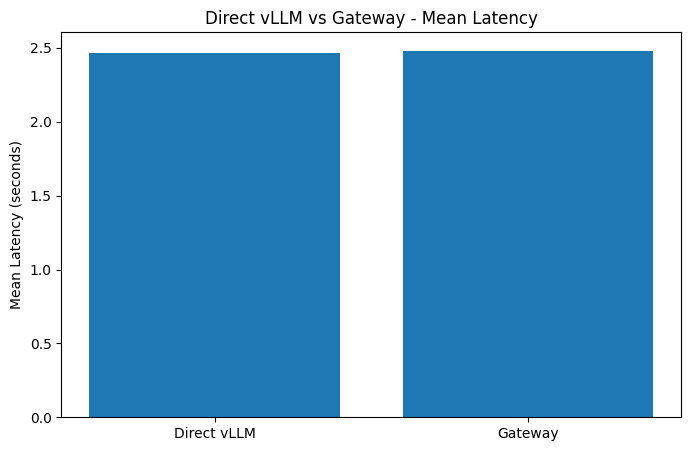

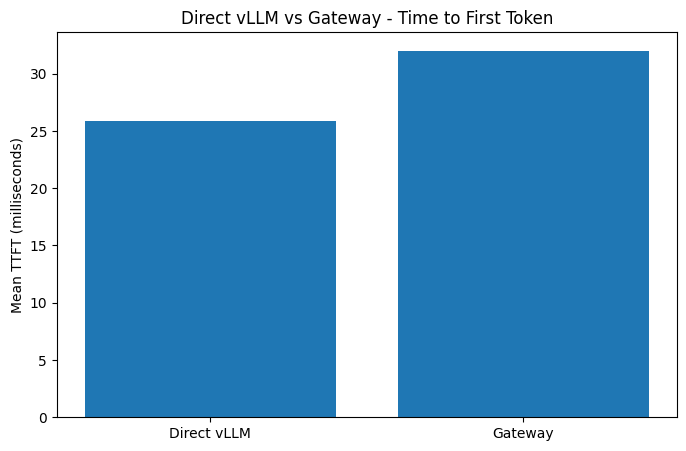

In [3]:
import matplotlib.pyplot as plt
import numpy as np

labels = ["Direct vLLM", "Gateway"]

latencies = [
    direct["latency_mean_sec"],
    gateway["latency_mean_sec"]
]

ttft = [
    direct["ttft_mean_sec"] * 1000,
    gateway["ttft_mean_sec"] * 1000
]

plt.figure(figsize=(8, 5))
plt.bar(labels, latencies)
plt.ylabel("Mean Latency (seconds)")
plt.title("Direct vLLM vs Gateway - Mean Latency")
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(labels, ttft)
plt.ylabel("Mean TTFT (milliseconds)")
plt.title("Direct vLLM vs Gateway - Time to First Token")
plt.show()

,gpu_index,name,gpu_util_pct,mem_util_pct,memory_used_mib,memory_total_mib
0,0,Tesla T4,78.0,74.0,10235.0,15360.0
1,1,Tesla T4,0.0,0.0,3.0,15360.0


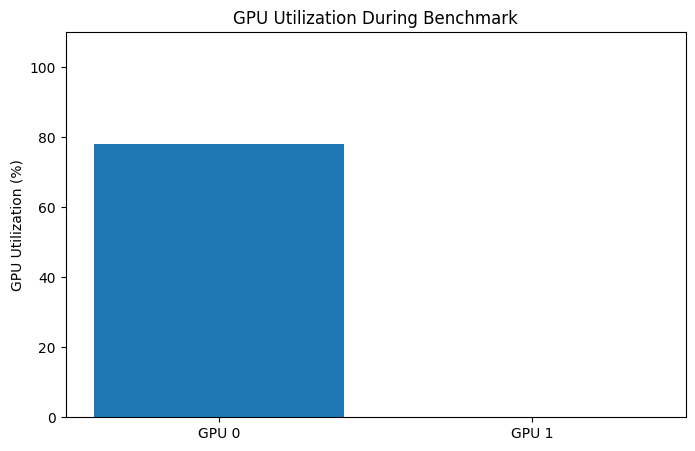

In [4]:
gpu_data = results["hardware"]

gpu_df = pd.DataFrame(gpu_data)

display(gpu_df)

plt.figure(figsize=(8, 5))
plt.bar(
    ["GPU 0", "GPU 1"],
    gpu_df["gpu_util_pct"]
)
plt.ylabel("GPU Utilization (%)")
plt.title("GPU Utilization During Benchmark")
plt.ylim(0, 110)
plt.show()

In [5]:
failures = [
    run for run in results["raw_gateway_runs"]
    if not run["success"]
]

print("Total Gateway failures:", len(failures))

for i, failure in enumerate(failures, 1):
    print(f"\nFailure {i}")
    print("HTTP Status:", failure["status_code"])
    print("Latency:", failure["latency_sec"], "seconds")
    print("Error:", failure["error"])

Total Gateway failures: 2

Failure 1
HTTP Status: 503
Latency: 0.0035713180000129796 seconds
Error: 503 Server Error: Service Unavailable for url: http://127.0.0.1:8000/v1/chat/completions

Failure 2
HTTP Status: 503
Latency: 0.002190804999827378 seconds
Error: 503 Server Error: Service Unavailable for url: http://127.0.0.1:8000/v1/chat/completions


In [1]:

import os
import subprocess
import socket
import requests
import torch

print("=" * 60)
print("CONFIDENTIALKV-SCHEDULER — ENVIRONMENT CHECK")
print("=" * 60)

# 1. GPU information
print("\n[1] GPU STATUS")

if torch.cuda.is_available():
    print("CUDA available:", True)
    print("GPU count:", torch.cuda.device_count())

    for i in range(torch.cuda.device_count()):
        print(f"\nGPU {i}: {torch.cuda.get_device_name(i)}")
        print(
            "Allocated memory:",
            round(torch.cuda.memory_allocated(i) / 1024**3, 2),
            "GB"
        )
        print(
            "Reserved memory:",
            round(torch.cuda.memory_reserved(i) / 1024**3, 2),
            "GB"
        )
else:
    print("CUDA available: False")

# 2. Running processes
print("\n[2] RELEVANT RUNNING PROCESSES")

result = subprocess.run(
    ["bash", "-lc", "ps -eo pid,cmd | grep -E 'vllm|uvicorn|opa' | grep -v grep"],
    capture_output=True,
    text=True
)

print(result.stdout if result.stdout.strip() else "No matching processes found.")

# 3. Check service ports
print("\n[3] SERVICE PORT CHECK")

for port in [8000, 8001, 8181]:
    sock = socket.socket()
    sock.settimeout(2)
    status = sock.connect_ex(("127.0.0.1", port))
    sock.close()

    print(f"Port {port}: {'OPEN' if status == 0 else 'CLOSED'}")

# 4. Check vLLM API
print("\n[4] vLLM API CHECK")

for endpoint in [
    "http://127.0.0.1:8001/health",
    "http://127.0.0.1:8001/v1/models"
]:
    try:
        response = requests.get(endpoint, timeout=5)
        print(f"\n{endpoint}")
        print("HTTP status:", response.status_code)
        print(response.text[:1000])
    except requests.RequestException as e:
        print(f"\n{endpoint}")
        print("Unavailable:", str(e))

print("\n" + "=" * 60)
print("ENVIRONMENT CHECK COMPLETE")
print("=" * 60)


CONFIDENTIALKV-SCHEDULER — ENVIRONMENT CHECK

[1] GPU STATUS
CUDA available: True
GPU count: 2

GPU 0: Tesla T4
Allocated memory: 0.0 GB
Reserved memory: 0.0 GB

GPU 1: Tesla T4
Allocated memory: 0.0 GB
Reserved memory: 0.0 GB

[2] RELEVANT RUNNING PROCESSES
No matching processes found.

[3] SERVICE PORT CHECK
Port 8000: CLOSED
Port 8001: CLOSED
Port 8181: CLOSED

[4] vLLM API CHECK

http://127.0.0.1:8001/health
Unavailable: HTTPConnectionPool(host='127.0.0.1', port=8001): Max retries exceeded with url: /health (Caused by NewConnectionError("HTTPConnection(host='127.0.0.1', port=8001): Failed to establish a new connection: [Errno 111] Connection refused"))

http://127.0.0.1:8001/v1/models
Unavailable: HTTPConnectionPool(host='127.0.0.1', port=8001): Max retries exceeded with url: /v1/models (Caused by NewConnectionError("HTTPConnection(host='127.0.0.1', port=8001): Failed to establish a new connection: [Errno 111] Connection refused"))

ENVIRONMENT CHECK COMPLETE


In [2]:

import os
from pathlib import Path

print("CURRENT DIRECTORY:", os.getcwd())

print("\nPROJECT DIRECTORIES:")
for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
    print(f"\n--- {root} ---")

    if root.exists():
        for item in list(root.iterdir())[:30]:
            print(item)

print("\nSEARCHING FOR PROJECT ENTRY POINTS:")

for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
    if not root.exists():
        continue

    for filename in ["main.py", "pyproject.toml", "requirements.txt", "authz.rego"]:
        matches = list(root.rglob(filename))
        for match in matches[:10]:
            print(match)


CURRENT DIRECTORY: /kaggle/working

PROJECT DIRECTORIES:

--- /kaggle/working ---
/kaggle/working/.virtual_documents

--- /kaggle/input ---
/kaggle/input/datasets

SEARCHING FOR PROJECT ENTRY POINTS:


In [3]:

from pathlib import Path

base = Path("/kaggle/input")

print("KAGGLE INPUT FILES")
print("=" * 60)

for path in base.rglob("*"):
    if path.is_file():
        print(path)

print("\n" + "=" * 60)
print("KAGGLE WORKING DIRECTORY")
print("=" * 60)

for path in Path("/kaggle/working").rglob("*"):
    if path.is_file():
        print(path)


KAGGLE INPUT FILES
/kaggle/input/datasets/adityamuthyala/corrected-benchmark/CKV_CORRECTED_GPU_BENCHMARK_RESULTS.json

KAGGLE WORKING DIRECTORY
/kaggle/working/.virtual_documents/__notebook_source__.ipynb


In [4]:

import os
import subprocess
from pathlib import Path

repo_url = "https://github.com/aditya3275/conf-kv-1.git"
repo_dir = Path("/kaggle/working/conf-kv-1")

if repo_dir.exists():
    print("Repository directory already exists.")
else:
    result = subprocess.run(
        ["git", "clone", repo_url, str(repo_dir)],
        text=True,
        capture_output=True
    )

    print(result.stdout)
    print(result.stderr)

    if result.returncode != 0:
        raise RuntimeError("Git clone failed. Check the error above.")

print("\nREPOSITORY CONTENTS")
print("=" * 60)

for item in sorted(repo_dir.iterdir()):
    print(("[DIR]  " if item.is_dir() else "[FILE] ") + item.name)

print("\nIMPORTANT PROJECT FILES")
print("=" * 60)

for name in [
    "README.md",
    "requirements.txt",
    "pyproject.toml",
    "main.py",
    "docker-compose.yml"
]:
    path = repo_dir / name
    if path.exists():
        print("FOUND:", path)



Cloning into '/kaggle/working/conf-kv-1'...


REPOSITORY CONTENTS
[FILE] .env.example
[DIR]  .git
[FILE] .gitignore
[FILE] README.md
[DIR]  app
[FILE] case.pages
[FILE] case.pdf
[DIR]  configs
[DIR]  data
[DIR]  docs
[FILE] phase8_context.txt
[DIR]  policies
[FILE] pytest.ini
[FILE] requirements.txt
[DIR]  scripts
[DIR]  tests
[DIR]  verifkv_service

IMPORTANT PROJECT FILES
FOUND: /kaggle/working/conf-kv-1/README.md
FOUND: /kaggle/working/conf-kv-1/requirements.txt


In [5]:

from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")

for filename in ["README.md", "requirements.txt", "pyproject.toml"]:
    path = repo / filename

    if path.exists():
        print(f"\n{'=' * 25} {filename} {'=' * 25}")
        print(path.read_text(errors="replace")[:12000])



========================= README.md =========================
cat > README.md <<'EOF'
# Conf-kv-1

ConfidentialKV-Scheduler

External policy control plane for multi-tenant LLM inference.

## Current Phase

Phase 1 — Foundation + Contracts
EOF

========================= requirements.txt =========================
fastapi>=0.115,<1.0
uvicorn[standard]>=0.34,<1.0

pydantic>=2.10,<3.0
pydantic-settings>=2.7,<3.0

httpx>=0.28,<1.0

aiosqlite>=0.20,<1.0

PyYAML>=6.0,<7.0

pytest>=8.3,<9.0
pytest-asyncio>=0.25,<1.0

python-dotenv>=1.0,<2.0


In [14]:

import subprocess
from pathlib import Path

venv = Path("/kaggle/working/vllm-env")

result = subprocess.run(
    [
        "uv", "venv",
        "--python", "/usr/bin/python3.12",
        str(venv)
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Virtual environment creation failed.")

python = venv / "bin" / "python"

subprocess.run([str(python), "--version"], check=True)

print("\nVirtual environment created:", venv)



Using CPython 3.12.3 interpreter at: /usr/bin/python3.12
Creating virtual environment at: vllm-env
Activate with: source vllm-env/bin/activate

Python 3.12.3

Virtual environment created: /kaggle/working/vllm-env


In [15]:

import subprocess

venv_python = "/kaggle/working/vllm-env/bin/python"

result = subprocess.run(
    [
        "uv", "pip", "install",
        "--python", venv_python,
        "vllm",
        "--torch-backend=auto"
    ],
    text=True
)

if result.returncode != 0:
    raise RuntimeError("vLLM installation failed. Share the error output.")

print("vLLM installation completed.")


Using Python 3.12.3 environment at: vllm-env
Resolved 199 packages in 1.95s
Prepared 199 packages in 56.52s
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.


vLLM installation completed.


Installed 199 packages in 28.39s
 + agent-detector==2.0.0
 + aiohappyeyeballs==2.7.1
 + aiohttp==3.14.5
 + aiosignal==1.4.0
 + annotated-doc==0.0.6
 + annotated-types==0.8.0
 + anthropic==2.8.0
 + anyio==4.16.0
 + apache-tvm-ffi==0.1.11
 + astor==0.8.1
 + attrs==26.1.0
 + blake3==1.0.11
 + cachetools==8.0.0
 + cbor2==6.2.1
 + certifi==2026.10.23
 + cffi==2.1.1
 + charset-normalizer==3.5.2
 + click==8.5.1
 + cloudpickle==3.1.2
 + compressed-tensors==0.17.0
 + cryptography==50.0.2
 + cuda-bindings==13.5.0
 + cuda-core==1.2.2
 + cuda-pathfinder==1.8.6
 + cuda-python==13.5.0
 + cuda-tile==1.8.0
 + cuda-toolkit==13.2.1
 + depyf==0.20.0
 + detect-installer==0.2.1
 + dill==0.4.1
 + dnspython==2.9.2
 + docstring-parser==0.18.0
 + einops==0.8.2
 + email-validator==2.3.0
 + fastapi==0.136.3
 + fastapi-cli==0.0.33
 + fastapi-cloud-cli==0.27.1
 + fastar==0.12.0
 + fastsafetensors==0.5.0
 + filelock==4.2.10
 + flashinfer-python==0.7.2.post1
 + frozenlist==1.8.0
 + fsspec==2026.9.0
 + googleapis-com

In [16]:

import subprocess

python = "/kaggle/working/vllm-env/bin/python"

code = """
import sys
import torch
import vllm

print("Python:", sys.version)
print("vLLM:", vllm.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
"""

result = subprocess.run(
    [python, "-c", code],
    capture_output=True,
    text=True
)

print(result.stdout)
if result.stderr:
    print("ERROR OUTPUT:")
    print(result.stderr[-4000:])

if result.returncode != 0:
    raise RuntimeError("vLLM environment verification failed.")


Python: 3.12.3 (main, Jul 15 2026, 23:46:41) [GCC 13.3.0]
vLLM: 0.33.0
PyTorch: 2.14.0+cu132
CUDA available: True
GPU 0: Tesla T4
GPU 1: Tesla T4



In [17]:

import os
import subprocess
import time
from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")
python = "/kaggle/working/vllm-env/bin/python"
log_path = Path("/kaggle/working/vllm_server.log")

model = "Qwen/Qwen2.5-1.5B-Instruct"

env = os.environ.copy()
env["CUDA_VISIBLE_DEVICES"] = "0"

log_file = open(log_path, "w")

command = [
    python, "-m", "vllm.entrypoints.openai.api_server",
    "--model", model,
    "--host", "127.0.0.1",
    "--port", "8001",
    "--dtype", "half",
    "--tensor-parallel-size", "1",
    "--max-model-len", "2048",
    "--gpu-memory-utilization", "0.85",
    "--max-num-seqs", "4"
]

process = subprocess.Popen(
    command,
    cwd=str(repo),
    env=env,
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("vLLM process started.")
print("PID:", process.pid)
print("Model:", model)
print("GPU: 0 (Tesla T4)")
print("API port: 8001")
print("Log file:", log_path)
print("\nAllow a few minutes for model loading.")


vLLM process started.
PID: 256
Model: Qwen/Qwen2.5-1.5B-Instruct
GPU: 0 (Tesla T4)
API port: 8001
Log file: /kaggle/working/vllm_server.log

Allow a few minutes for model loading.


In [19]:

import requests
import time
from pathlib import Path

url = "http://127.0.0.1:8001/health"

print("Waiting for vLLM...")

for attempt in range(60):
    try:
        response = requests.get(url, timeout=3)

        if response.status_code == 200:
            print("\nSUCCESS: vLLM is healthy!")
            break

    except requests.RequestException:
        pass

    time.sleep(5)
else:
    print("\nModel is not ready yet.")

log = Path("/kaggle/working/vllm_server.log")

if log.exists():
    print("\nLATEST SERVER LOGS:")
    print("\n".join(log.read_text(errors="replace").splitlines()[-35:]))


Waiting for vLLM...

SUCCESS: vLLM is healthy!

LATEST SERVER LOGS:
(APIServer pid=256) INFO 11-11 11:31:16 [launcher.py:197] Route: /version, Methods: GET
(APIServer pid=256) INFO 11-11 11:31:16 [launcher.py:197] Route: /kv_event_sources, Methods: GET
(APIServer pid=256) INFO 11-11 11:31:16 [launcher.py:197] Route: /health, Methods: GET
(APIServer pid=256) INFO 11-11 11:31:16 [launcher.py:197] Route: /metrics, Methods: GET
(APIServer pid=256) INFO 11-11 11:31:16 [launcher.py:197] Route: /tokenize, Methods: POST
(APIServer pid=256) INFO 11-11 11:31:16 [launcher.py:197] Route: /detokenize, Methods: POST
(APIServer pid=256) INFO 11-11 11:31:16 [launcher.py:197] Route: /v1/models, Methods: GET
(APIServer pid=256) INFO 11-11 11:31:16 [launcher.py:197] Route: /v1/systemone, Methods: POST
(APIServer pid=256) INFO 11-11 11:31:16 [launcher.py:197] Route: /v1/decisions, Methods: POST
(APIServer pid=256) INFO 11-11 11:31:16 [launcher.py:197] Route: /ping, Methods: GET
(APIServer pid=256) INFO 11

In [20]:

import requests
import json
import time

BASE_URL = "http://127.0.0.1:8001"

# 1. Verify the loaded model
response = requests.get(f"{BASE_URL}/v1/models", timeout=15)
response.raise_for_status()

models = response.json()
print("AVAILABLE MODELS:")
print(json.dumps(models, indent=2))

model_id = models["data"][0]["id"]

# 2. Send a real inference request
payload = {
    "model": model_id,
    "messages": [
        {
            "role": "user",
            "content": "Explain how a load balancer distributes incoming requests across multiple backend servers. Give a practical example."
        }
    ],
    "temperature": 0.2,
    "max_tokens": 180,
    "stream": False
}

print("\nSENDING LIVE INFERENCE REQUEST...")

start = time.perf_counter()

result = requests.post(
    f"{BASE_URL}/v1/chat/completions",
    json=payload,
    timeout=120
)

latency = time.perf_counter() - start
result.raise_for_status()

data = result.json()

print("\n" + "=" * 65)
print("LIVE MODEL RESPONSE")
print("=" * 65)
print(data["choices"][0]["message"]["content"])

print("\n" + "=" * 65)
print("INFERENCE METADATA")
print("=" * 65)
print("Model:", data["model"])
print("Prompt tokens:", data["usage"]["prompt_tokens"])
print("Completion tokens:", data["usage"]["completion_tokens"])
print("Total tokens:", data["usage"]["total_tokens"])
print("End-to-end latency:", round(latency, 3), "seconds")
print("HTTP status:", result.status_code)


AVAILABLE MODELS:
{
  "object": "list",
  "data": [
    {
      "id": "Qwen/Qwen2.5-1.5B-Instruct",
      "object": "model",
      "created": 1794396780,
      "owned_by": "vllm",
      "root": "Qwen/Qwen2.5-1.5B-Instruct",
      "parent": null,
      "max_model_len": 2048,
      "permission": [
        {
          "id": "modelperm-ac3207f7e99ed85c",
          "object": "model_permission",
          "created": 1794396780,
          "allow_create_engine": false,
          "allow_sampling": true,
          "allow_logprobs": true,
          "allow_search_indices": false,
          "allow_view": true,
          "allow_fine_tuning": false,
          "organization": "*",
          "group": null,
          "is_blocking": false
        }
      ]
    }
  ]
}

SENDING LIVE INFERENCE REQUEST...

LIVE MODEL RESPONSE
A load balancer is a device or software that distributes network traffic evenly among multiple servers to improve performance and availability of the system. It works by receiving inco

In [21]:

from pathlib import Path

p = Path("/kaggle/working/conf-kv-1/app/main.py")
lines = p.read_text().splitlines()

keywords = [
    "@asynccontextmanager",
    "lifespan",
    "app = FastAPI",
    "@app.get",
    "@app.post",
    "health",
    "startup",
    "VerifKVWriter",
    "OPAClient",
]

for i, line in enumerate(lines):
    if any(k in line for k in keywords):
        start = max(0, i - 2)
        end = min(len(lines), i + 5)

        print(f"\n--- Lines {start+1}-{end} ---")
        for j in range(start, end):
            print(f"{j+1}: {lines[j]}")



--- Lines 26-32 ---
26: from app.models.opa import OPARequest
27: from app.opa.client import (
28:     OPAClient,
29:     OPADecisionError,
30:     OPAUnavailableError,
31: )
32: from app.registry.backend_registry import BackendRegistry

--- Lines 31-37 ---
31: )
32: from app.registry.backend_registry import BackendRegistry
33: from app.registry.health_monitor import BackendHealthMonitor
34: from app.registry.tenant_registry import TenantRegistry
35: from app.scheduler.scheduler import (
36:     NoBackendAvailableError,
37:     SecurityAwareScheduler,

--- Lines 39-45 ---
39: from app.verifkv.client import VerifKVEventClient
40: from app.verifkv.store import VerifKVStore
41: from app.verifkv.writer import VerifKVWriter
42: 
43: logger = logging.getLogger(__name__)
44: 
45: 

--- Lines 112-118 ---
112: 
113: 
114: @asynccontextmanager
115: async def lifespan(app: FastAPI):
116:     """
117:     Initialize all control-plane dependencies before accepting traffic.
118:     """

--- Lines 

In [22]:

from pathlib import Path

p = Path("/kaggle/working/conf-kv-1/app/main.py")
lines = p.read_text().splitlines()

for i, line in enumerate(lines):
    if "lifespan" in line or "app = FastAPI" in line:
        print(f"\nLine {i+1}:")
        print("\n".join(lines[i:i+12]))



Line 115:
async def lifespan(app: FastAPI):
    """
    Initialize all control-plane dependencies before accepting traffic.
    """

    tenant_registry = TenantRegistry(settings.tenant_db_path)

    backend_registry = BackendRegistry(settings.control_plane_db_path)

    opa_client = OPAClient(
        base_url=settings.opa_url,
        timeout_seconds=settings.opa_timeout_seconds,

Line 285:
app = FastAPI(
    title=settings.app_name,
    lifespan=lifespan,
)


@app.middleware("http")
async def request_id_middleware(
    request: Request,
    call_next,
):
    """

Line 287:
    lifespan=lifespan,
)


@app.middleware("http")
async def request_id_middleware(
    request: Request,
    call_next,
):
    """
    Generate a gateway request ID and propagate it through the
    ContextVar-backed request context.


In [23]:

from pathlib import Path

lines = Path(
    "/kaggle/working/conf-kv-1/app/main.py"
).read_text().splitlines()

for i in range(115, 210):
    print(f"{i+1}: {lines[i]}")


116:     """
117:     Initialize all control-plane dependencies before accepting traffic.
118:     """
119: 
120:     tenant_registry = TenantRegistry(settings.tenant_db_path)
121: 
122:     backend_registry = BackendRegistry(settings.control_plane_db_path)
123: 
124:     opa_client = OPAClient(
125:         base_url=settings.opa_url,
126:         timeout_seconds=settings.opa_timeout_seconds,
127:     )
128: 
129:     # ------------------------------------------------------------------
130:     # VerifKV asynchronous event client
131:     # ------------------------------------------------------------------
132: 
133:     verifkv_client = VerifKVEventClient(
134:         base_url=settings.verifkv_url,
135:     )
136: 
137:     # ------------------------------------------------------------------
138:     # VerifKV durable authorization outbox + ordered writer
139:     # ------------------------------------------------------------------
140: 
141:     verifkv_store = VerifKVStore(
142:   

In [24]:

from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")

print("GATEWAY ROUTES:")
for i, line in enumerate((repo / "app/main.py").read_text().splitlines()):
    if line.strip().startswith("@app."):
        print(f"{i+1}: {line.strip()}")

print("\nOPA / VERIFKV STARTUP FILES:")
for name in ["Dockerfile", "docker-compose.yml", "compose.yaml"]:
    matches = list(repo.rglob(name))
    for p in matches:
        print(p.relative_to(repo))


GATEWAY ROUTES:
291: @app.middleware("http")
331: @app.get("/health")
339: @app.get("/ready")
351: @app.get("/metrics")
361: @app.post("/v1/chat/completions")

OPA / VERIFKV STARTUP FILES:


In [25]:

import shutil
from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")

print("SERVICE BINARIES")
for name in ["opa", "docker", "curl"]:
    print(f"{name}: {shutil.which(name) or 'NOT FOUND'}")

print("\nVERIFKV ENTRY POINT")
p = repo / "verifkv_service/main.py"
print(p.read_text()[:1200])

print("\nREQUIRED SETTINGS NAMES")
p = repo / "app/config/settings.py"

for line in p.read_text().splitlines():
    if ":" in line and "=" in line and not line.strip().startswith("#"):
        if any(k in line.lower() for k in [
            "secret", "tenant", "opa_policy", "database", "verifkv"
        ]):
            print(line.strip().split("=")[0].strip())


SERVICE BINARIES
opa: NOT FOUND
docker: NOT FOUND
curl: /usr/bin/curl

VERIFKV ENTRY POINT
import uvicorn

if __name__ == "__main__":
    uvicorn.run(
        "verifkv_service.app:app",
        host="127.0.0.1",
        port=8100,
        reload=False,
    )


REQUIRED SETTINGS NAMES
verifkv_url: str
verifkv_db_path: str
verifkv_reconcile_interval_seconds: float


In [26]:

from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")

# Gateway settings
p = repo / "app/config/settings.py"
lines = p.read_text().splitlines()

print("GATEWAY SETTINGS:")
for line in lines:
    if any(x in line.lower() for x in [
        "verifkv_url", "opa_url", "opa_policy_path",
        "hmac_secret", "tenant_db_path"
    ]):
        print(line.strip())

# VerifKV FastAPI application
p = repo / "verifkv_service/app.py"
print("\nVERIFKV ROUTES:")
for line in p.read_text().splitlines():
    if line.strip().startswith("@app."):
        print(line.strip())

# OPA policy
p = repo / "policies/rego/authz.rego"
print("\nOPA POLICY EXISTS:", p.exists())
print("OPA POLICY SIZE:", len(p.read_text()) if p.exists() else 0)



GATEWAY SETTINGS:
opa_url: str = "http://127.0.0.1:8181"
verifkv_url: str = "http://127.0.0.1:9000"
def tenant_db_path(self) -> str:
verifkv_hmac_secret: SecretStr

VERIFKV ROUTES:
@app.get("/health")
@app.post(
@app.get("/v1/verify")

OPA POLICY EXISTS: True
OPA POLICY SIZE: 3153


In [27]:

from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")

# Required Settings fields
p = repo / "app/config/settings.py"
lines = p.read_text().splitlines()

print("REQUIRED SETTINGS:")
for line in lines:
    if ":" in line and "=" not in line and not line.strip().startswith("#"):
        print(line.strip())

# VerifKV API implementation
p = repo / "verifkv_service/app.py"
lines = p.read_text().splitlines()

print("\nVERIFKV API HANDLERS:")
for i, line in enumerate(lines):
    if line.strip().startswith("@app."):
        print("\n".join(lines[i:i+7]))

# OPA policy package and rule
p = repo / "policies/rego/authz.rego"
print("\nOPA POLICY HEADER:")
print("\n".join(p.read_text().splitlines()[:12]))


REQUIRED SETTINGS:
class Settings(BaseSettings):
The control plane uses centralized configuration so that:
def tenant_db_path(self) -> str:
verifkv_hmac_secret: SecretStr
def get_settings() -> Settings:

VERIFKV API HANDLERS:
    @app.get("/health")
    async def health() -> dict:

        return {
            "status": "ok",
            "service": "verifkv",
        }
    @app.post(
        "/v1/events",
        status_code=status.HTTP_202_ACCEPTED,
    )
    async def ingest_event(
        event: VerifKVEvent,
    ) -> dict:
    @app.get("/v1/verify")
    async def verify_chain() -> dict:

        return state.store.verify_chain()

    return app


OPA POLICY HEADER:
package confidentialkv

import rego.v1


default allow := false


# ---------------------------------------------------------
# Main authorization decision
# ---------------------------------------------------------



In [28]:

from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")

# Settings fields
p = repo / "app/config/settings.py"
print("SETTINGS FIELDS:")
for line in p.read_text().splitlines():
    s = line.strip()
    if s.startswith(("app_name:", "opa_", "verifkv_", "tenant_", "control_plane_", "outbox_", "backend_", "health_", "upstream_")):
        print(s)

# OPA API contract
p = repo / "app/opa/client.py"
print("\nOPA CLIENT URLS:")
for line in p.read_text().splitlines():
    if any(x in line for x in ["/v1/", "requests.post", "base_url", "policy_path"]):
        print(line.strip())

# VerifKV event model
p = repo / "app/models/verifkv.py"
print("\nVERIFKV EVENT MODEL:")
print("\n".join(p.read_text().splitlines()[:65]))


SETTINGS FIELDS:
app_name: str = "ConfidentialKV-Scheduler Control Plane"
opa_url: str = "http://127.0.0.1:8181"
opa_timeout_seconds: float = 2.0
verifkv_url: str = "http://127.0.0.1:9000"
upstream_timeout_seconds: float = 60.0
control_plane_db_path: str = "data/control_plane.db"
outbox_db_path: str = "data/outbox.db"
verifkv_db_path: str = "data/verifkv.db"
verifkv_hmac_secret: SecretStr
health_cache_ttl_seconds: float = 5.0
health_check_timeout_seconds: float = 1.5
verifkv_reconcile_interval_seconds: float = 30.0

OPA CLIENT URLS:
base_url: str,
self.base_url = base_url.rstrip("/")
base_url=self.base_url,
"/v1/data/confidentialkv/authz",

VERIFKV EVENT MODEL:
from __future__ import annotations

from datetime import datetime, timezone
from enum import Enum
from typing import Any
from uuid import UUID, uuid4

from pydantic import BaseModel, Field

# Genesis value for the VerifKV tamper-evident hash chain.
GENESIS_HASH = "0" * 64


class VerifKVEventType(str, Enum):

    AUTHZ_DECISION 

In [29]:

from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")

print("SETTINGS DECLARATIONS:")
lines = (repo / "app/config/settings.py").read_text().splitlines()

for line in lines:
    s = line.strip()
    if s.startswith(("app_name:", "opa_", "verifkv_", "tenant_", "control_plane_", "outbox_", "health_", "upstream_", "database_", "secret")):
        print(s)

print("\nOPA CLIENT REQUEST STRUCTURE:")
lines = (repo / "app/opa/client.py").read_text().splitlines()

for i, line in enumerate(lines):
    if "json=" in line or "client.post" in line or "raise_for_status" in line:
        print("\n".join(lines[max(0, i-3):min(len(lines), i+5)]))

print("\nPLATFORM:", __import__("platform").machine())


SETTINGS DECLARATIONS:
app_name: str = "ConfidentialKV-Scheduler Control Plane"
opa_url: str = "http://127.0.0.1:8181"
opa_timeout_seconds: float = 2.0
verifkv_url: str = "http://127.0.0.1:9000"
upstream_timeout_seconds: float = 60.0
control_plane_db_path: str = "data/control_plane.db"
outbox_db_path: str = "data/outbox.db"
verifkv_db_path: str = "data/verifkv.db"
verifkv_hmac_secret: SecretStr
health_cache_ttl_seconds: float = 5.0
health_check_timeout_seconds: float = 1.5
verifkv_reconcile_interval_seconds: float = 30.0

OPA CLIENT REQUEST STRUCTURE:
        client = self._require_client()

        try:
            response = await client.post(
                "/v1/data/confidentialkv/authz",
                json=request.model_dump(mode="json"),
            )

        try:
            response = await client.post(
                "/v1/data/confidentialkv/authz",
                json=request.model_dump(mode="json"),
            )

            response.raise_for_status()

              

In [30]:

import subprocess
from pathlib import Path

opa_path = Path("/kaggle/working/opa")

subprocess.run(
    [
        "curl", "-L", "--fail",
        "-o", str(opa_path),
        "https://openpolicyagent.org/downloads/latest/opa_linux_amd64"
    ],
    check=True
)

opa_path.chmod(0o755)

result = subprocess.run(
    [str(opa_path), "version"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    raise RuntimeError(result.stderr)


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100    79  100    79    0     0   1191      0 --:--:-- --:--:-- --:--:--  1196
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
 18 61.2M   18 11.5M    0     0  14.2M      0  0:00:04 --:--:--  0:00:04 14.2M

Version: 1.22.3
Build Commit: 32b01b6b3268531be9fb1c37be2c7788f6afc08e-dirty
Build Timestamp: 2026-11-10T12:36:50Z
Build Hostname: 
Go Version: go1.27.3
Platform: linux/amd64
Rego Version: v1
WebAssembly: available



100 61.2M  100 61.2M    0     0  39.2M      0  0:00:01  0:00:01 --:--:-- 66.3M


In [31]:

import subprocess

repo = "/kaggle/working/conf-kv-1"

result = subprocess.run(
    [
        "/kaggle/working/opa",
        "check",
        f"{repo}/policies/rego/authz.rego"
    ],
    capture_output=True,
    text=True
)

print("POLICY VALIDATION:")
print(result.stdout or result.stderr or "No errors reported.")

if result.returncode != 0:
    raise RuntimeError("OPA policy validation failed.")


POLICY VALIDATION:
No errors reported.


In [32]:

import subprocess
import time
import requests
from pathlib import Path

opa = "/kaggle/working/opa"
policy = "/kaggle/working/conf-kv-1/policies/rego/authz.rego"
log_path = "/kaggle/working/opa_server.log"

# Start OPA with the actual project policy
log_file = open(log_path, "w")

process = subprocess.Popen(
    [
        opa,
        "run",
        "--server",
        "--addr=127.0.0.1:8181",
        policy
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("OPA process started. PID:", process.pid)

# Wait for OPA health
for attempt in range(20):
    try:
        response = requests.get(
            "http://127.0.0.1:8181/health",
            timeout=2
        )

        if response.status_code == 200:
            print("\nSUCCESS: OPA is running!")
            print("HTTP status:", response.status_code)
            break

    except requests.RequestException:
        pass

    time.sleep(2)

else:
    print("\nOPA did not become healthy.")
    print(Path(log_path).read_text(errors="replace")[-3000:])


OPA process started. PID: 520

SUCCESS: OPA is running!
HTTP status: 200


In [33]:

import requests

url = "http://127.0.0.1:8181/v1/data/confidentialkv/authz"

response = requests.get(url, timeout=5)

print("OPA API status:", response.status_code)
print("Response:", response.text[:1000])


OPA API status: 200
Response: {}



In [34]:

import subprocess
import time
import requests
from pathlib import Path

repo = "/kaggle/working/conf-kv-1"
python = "/kaggle/working/vllm-env/bin/python"
log_path = "/kaggle/working/verifkv_server.log"

log_file = open(log_path, "w")

process = subprocess.Popen(
    [
        python, "-m", "uvicorn",
        "verifkv_service.app:app",
        "--host", "127.0.0.1",
        "--port", "9000"
    ],
    cwd=repo,
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("VerifKV PID:", process.pid)

for attempt in range(20):
    try:
        response = requests.get(
            "http://127.0.0.1:9000/health",
            timeout=3
        )

        if response.status_code == 200:
            print("VerifKV HEALTH:", response.json())
            break

    except requests.RequestException:
        pass

    time.sleep(2)

else:
    print("VerifKV did not become healthy.")
    print(Path(log_path).read_text(errors="replace")[-3000:])


VerifKV PID: 535
VerifKV HEALTH: {'status': 'ok', 'service': 'verifkv'}


In [35]:

import os
import secrets

secret = os.environ.get("VERIFKV_HMAC_SECRET")

if not secret:
    secret = secrets.token_hex(32)
    os.environ["VERIFKV_HMAC_SECRET"] = secret
    print("Generated a temporary HMAC secret for this Kaggle session.")
else:
    print("Existing HMAC secret found; preserving it.")

print("Secret configured:", bool(secret))
print("Secret length:", len(secret))


Generated a temporary HMAC secret for this Kaggle session.
Secret configured: True
Secret length: 64


In [36]:

import subprocess
import time
import requests
from pathlib import Path

repo = "/kaggle/working/conf-kv-1"
python = "/kaggle/working/vllm-env/bin/python"
log_path = "/kaggle/working/gateway_server.log"

env = os.environ.copy()
env["OPA_URL"] = "http://127.0.0.1:8181"
env["VERIFKV_URL"] = "http://127.0.0.1:9000"

log_file = open(log_path, "w")

process = subprocess.Popen(
    [
        python, "-m", "uvicorn",
        "app.main:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    cwd=repo,
    env=env,
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("Gateway PID:", process.pid)

for attempt in range(30):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/health",
            timeout=3
        )

        if response.status_code == 200:
            print("GATEWAY HEALTH:", response.json())
            break

    except requests.RequestException:
        pass

    time.sleep(2)

else:
    print("Gateway did not become healthy.")
    print(Path(log_path).read_text(errors="replace")[-4000:])


Gateway PID: 546
Gateway did not become healthy.
Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/kaggle/working/vllm-env/lib/python3.12/site-packages/uvicorn/__main__.py", line 4, in <module>
    uvicorn.main()
  File "/kaggle/working/vllm-env/lib/python3.12/site-packages/click/core.py", line 1653, in __call__
    return self.main(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/kaggle/working/vllm-env/lib/python3.12/site-packages/click/core.py", line 1560, in main
    rv = self.invoke(ctx)
         ^^^^^^^^^^^^^^^^
  File "/kaggle/working/vllm-env/lib/python3.12/site-packages/click/core.py", line 1414, in invoke
    return ctx.invoke(self.callback, **ctx.params)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/kaggle/working/vllm-env/lib/python3.12/site-packages/click/core.py", line 911, in invoke
    return callback(*args, **kwargs)
           ^^^^^^^^^^^^^^^

In [37]:

import subprocess

python = "/kaggle/working/vllm-env/bin/python"
requirements = "/kaggle/working/conf-kv-1/requirements.txt"

result = subprocess.run(
    [
        "uv", "pip", "install",
        "--python", python,
        "-r", requirements
    ],
    text=True
)

if result.returncode != 0:
    raise RuntimeError("Dependency installation failed.")

print("Project dependencies installed successfully.")


Project dependencies installed successfully.


Using Python 3.12.3 environment at: vllm-env
Resolved 30 packages in 125ms
Prepared 5 packages in 25ms
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 5 packages in 15ms
 + aiosqlite==0.22.1
 + iniconfig==2.3.1
 + pluggy==1.7.0
 + pytest==8.4.2
 + pytest-asyncio==0.26.0


In [38]:

import subprocess

result = subprocess.run(
    [
        "/kaggle/working/vllm-env/bin/python",
        "-c",
        "import fastapi, uvicorn, aiosqlite, httpx, pydantic; print('All core imports successful')"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Dependency verification failed.")


All core imports successful




In [39]:

import os
import subprocess
import time
import requests
from pathlib import Path

repo = "/kaggle/working/conf-kv-1"
python = "/kaggle/working/vllm-env/bin/python"
log_path = "/kaggle/working/gateway_server.log"

env = os.environ.copy()
env["OPA_URL"] = "http://127.0.0.1:8181"
env["VERIFKV_URL"] = "http://127.0.0.1:9000"

log_file = open(log_path, "w")

process = subprocess.Popen(
    [
        python, "-m", "uvicorn",
        "app.main:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    cwd=repo,
    env=env,
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("Gateway PID:", process.pid)

for attempt in range(30):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/health",
            timeout=3
        )

        if response.status_code == 200:
            print("GATEWAY HEALTH:", response.json())
            break

    except requests.RequestException:
        pass

    time.sleep(2)

else:
    print("Gateway startup failed:")
    print(Path(log_path).read_text(errors="replace")[-3000:])


Gateway PID: 575
GATEWAY HEALTH: {'status': 'ok', 'service': 'ConfidentialKV-Scheduler Control Plane'}


In [40]:

from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")

# Available backend zones
p = repo / "app/models/enums.py"
lines = p.read_text().splitlines()

print("BACKEND ZONES:")
for i, line in enumerate(lines):
    if "class Zone" in line:
        print("\n".join(lines[i:i+12]))
        break

# Tenant creation arguments
p = repo / "scripts/create_tenant.py"
print("\nTENANT CREATION OPTIONS:")
for line in p.read_text().splitlines():
    if "add_argument" in line or "required=" in line or "default=" in line:
        print(line.strip())

# Inference request fields
p = repo / "app/models/inference.py"
print("\nINFERENCE REQUEST MODEL:")
lines = p.read_text().splitlines()
for i, line in enumerate(lines):
    if "class ClientInferenceRequest" in line:
        print("\n".join(lines[i:i+22]))
        break


BACKEND ZONES:
class Zone(str, Enum):
    SECURE = "secure"
    GENERAL = "general"


class BackendStatus(str, Enum):
    AVAILABLE = "available"
    UNAVAILABLE = "unavailable"


class HealthStatus(str, Enum):
    HEALTHY = "healthy"

TENANT CREATION OPTIONS:
parser.add_argument(
required=True,
parser.add_argument(
required=True,
parser.add_argument(
required=True,
parser.add_argument(
default=1000,
parser.add_argument(
kv_isolation_required=not args.no_kv_isolation,

INFERENCE REQUEST MODEL:
class ClientInferenceRequest(BaseModel):
    """
    Trusted boundary model for the client payload.

    tenant_id is intentionally absent.
    Tenant identity comes from authentication, not the request body.
    """

    model_config = ConfigDict(extra="allow")

    model: str = Field(min_length=1)

    messages: list[dict[str, Any]] = Field(min_length=1)

    stream: bool = True

    max_tokens: int | None = None

    temperature: float | None = None

    parameters: dict[str, Any] = Field(defa

In [41]:

from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")

p = repo / "scripts/create_tenant.py"
lines = p.read_text().splitlines()

print("TENANT CREATION SCRIPT:")
print("\n".join(lines[:85]))

print("\nTENANT AUTHENTICATION:")
p = repo / "app/gateway/auth.py"
print("\n".join(p.read_text().splitlines()[:65]))


TENANT CREATION SCRIPT:
from __future__ import annotations

import argparse
import asyncio

from app.config.settings import get_settings
from app.models.enums import SecurityLevel, Zone
from app.registry.tenant_registry import TenantRegistry


def build_parser() -> argparse.ArgumentParser:
    parser = argparse.ArgumentParser(
        description="Create a ConfidentialKV-Scheduler tenant"
    )

    parser.add_argument(
        "--id",
        required=True,
        dest="tenant_id",
    )

    parser.add_argument(
        "--security-level",
        required=True,
        choices=[level.value for level in SecurityLevel],
    )

    parser.add_argument(
        "--zones",
        required=True,
        nargs="+",
        choices=[zone.value for zone in Zone],
    )

    parser.add_argument(
        "--quota",
        type=int,
        default=1000,
    )

    parser.add_argument(
        "--no-kv-isolation",
        action="store_true",
    )

    return parser


async def main() -> No

In [42]:

from pathlib import Path

repo = Path("/kaggle/working/conf-kv-1")

# Security levels
p = repo / "app/models/enums.py"
lines = p.read_text().splitlines()

for i, line in enumerate(lines):
    if "class SecurityLevel" in line:
        print("SECURITY LEVELS:")
        print("\n".join(lines[i:i+10]))
        break

# Existing policy test cases
p = repo / "policies/rego/authz_test.rego"
print("\nPOLICY TEST CASE NAMES:")
for line in p.read_text().splitlines():
    if line.strip().startswith("test_"):
        print(line.strip())


SECURITY LEVELS:
class SecurityLevel(str, Enum):
    HIGH = "high"
    STANDARD = "standard"


class Zone(str, Enum):
    SECURE = "secure"
    GENERAL = "general"



POLICY TEST CASE NAMES:
test_high_security_secure_backend_allowed if {
test_high_security_general_backend_denied if {
test_inactive_tenant_denied if {
test_exhausted_quota_denied if {
test_unhealthy_backend_denied if {
test_capacity_unavailable_denied if {
test_backend_mismatch_denied if {


In [45]:

import subprocess
import os

repo = "/kaggle/working/conf-kv-1"
python = "/kaggle/working/vllm-env/bin/python"

env = os.environ.copy()
env["PYTHONPATH"] = repo

command = [
    python, "scripts/register_backend.py",
    "--id", "qwen-t4-0",
    "--endpoint", "http://127.0.0.1:8001",
    "--zone", "secure",
    "--gpu", "0",
    "--available"
]

result = subprocess.run(
    command,
    cwd=repo,
    env=env,
    capture_output=True,
    text=True
)

print("EXIT CODE:", result.returncode)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)

if result.returncode != 0:
    raise RuntimeError("Backend registration failed.")


EXIT CODE: 0
STDOUT: Registered backend: qwen-t4-0

STDERR: 


In [46]:

import subprocess
import os

repo = "/kaggle/working/conf-kv-1"
python = "/kaggle/working/vllm-env/bin/python"

env = os.environ.copy()
env["PYTHONPATH"] = repo

command = [
    python, "scripts/create_tenant.py",
    "--id", "demo-tenant-01",
    "--security-level", "high",
    "--zones", "secure",
    "--quota", "1000"
]

result = subprocess.run(
    command,
    cwd=repo,
    env=env,
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Tenant creation failed.")

print(result.stdout.split("API key")[0].strip())

lines = result.stdout.splitlines()
tenant_api_key = lines[-1].strip()

if not tenant_api_key:
    raise RuntimeError("API key was not captured.")

print("\nTenant API key captured in notebook memory.")
print("Key length:", len(tenant_api_key))


Created tenant: demo-tenant-01

Tenant API key captured in notebook memory.
Key length: 47


In [47]:

from pathlib import Path

p = Path("/kaggle/working/conf-kv-1/policies/rego/authz.rego")
lines = p.read_text().splitlines()

for i, line in enumerate(lines):
    if any(x in line.lower() for x in [
        "security_level",
        "allowed_zones",
        "zone ==",
        "zone in",
        "tenant.active",
        "quota"
    ]):
        print(f"{i+1}: {line.strip()}")


14: input.tenant.active
15: input.tenant.quota_remaining > 0
19: input.recommendation.zone in input.tenant.allowed_zones
30: input.tenant.security_level == "standard"
35: input.tenant.security_level == "high"
36: input.recommendation.zone == "secure"
45: not input.tenant.active
48: reason := "quota_exhausted" if {
49: input.tenant.active
50: input.tenant.quota_remaining <= 0
54: input.tenant.active
55: input.tenant.quota_remaining > 0
61: not input.recommendation.zone in input.tenant.allowed_zones
66: input.recommendation.zone in input.tenant.allowed_zones
82: input.tenant.security_level == "high"


In [48]:

from pathlib import Path

p = Path("/kaggle/working/conf-kv-1/policies/rego/authz.rego")
lines = p.read_text().splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(25, 42)
))


26: }
27: 
28: 
29: high_security_requirement_satisfied if {
30:     input.tenant.security_level == "standard"
31: }
32: 
33: 
34: high_security_requirement_satisfied if {
35:     input.tenant.security_level == "high"
36:     input.recommendation.zone == "secure"
37: }
38: 
39: 
40: # ---------------------------------------------------------
41: # Human-readable reason
42: # ---------------------------------------------------------


In [49]:

import subprocess
import os

repo = "/kaggle/working/conf-kv-1"
python = "/kaggle/working/vllm-env/bin/python"

env = os.environ.copy()
env["PYTHONPATH"] = repo

tenants = [
    {
        "id": "demo-tenant-02",
        "security": "standard",
        "zones": ["secure", "general"]
    },
    {
        "id": "demo-tenant-03",
        "security": "high",
        "zones": ["general"]
    }
]

tenant_keys = {}

for tenant in tenants:
    command = [
        python, "scripts/create_tenant.py",
        "--id", tenant["id"],
        "--security-level", tenant["security"],
        "--zones", *tenant["zones"],
        "--quota", "1000"
    ]

    result = subprocess.run(
        command,
        cwd=repo,
        env=env,
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        print(tenant["id"], "FAILED")
        print(result.stderr[-1500:])
        continue

    key = result.stdout.splitlines()[-1].strip()
    tenant_keys[tenant["id"]] = key

    print(tenant["id"], "CREATED")
    print("API key captured. Length:", len(key))

print("\nTenants created:", len(tenant_keys))


demo-tenant-02 CREATED
API key captured. Length: 47
demo-tenant-03 CREATED
API key captured. Length: 47

Tenants created: 2


In [55]:
import psutil, subprocess, os, time

for p in psutil.process_iter(["pid", "cmdline"]):
    cmd = " ".join(p.info["cmdline"] or [])
    if "uvicorn" in cmd and "app.main:app" in cmd and "--port 8000" in cmd:
        p.kill()
        p.wait()

repo = "/kaggle/working/conf-kv-1"
env = os.environ.copy()
env["PYTHONPATH"] = repo

gateway_process = subprocess.Popen(
    [
        "/kaggle/working/vllm-env/bin/python",
        "-m", "uvicorn", "app.main:app",
        "--host", "127.0.0.1", "--port", "8000"
    ],
    cwd=repo,
    env=env,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(3)

print("Gateway restarted:", gateway_process.poll() is None)
print("Health:", requests.get("http://127.0.0.1:8000/health").status_code)

Gateway restarted: True
Health: 200


In [59]:
from pathlib import Path

p = Path("/kaggle/working/conf-kv-1/app/scheduler/scheduler.py")
s = p.read_text()

for i, line in enumerate(s.splitlines()):
    if "allowed_zones" in line or "zone" in line.lower():
        print(f"{i+1}: {line.strip()}")

7: Zone,
70: zone=selected.zone,
91: if backend.zone not in tenant.allowed_zones:
104: High-security tenants prefer secure zones.
105: Among equally suitable zones, lower load wins.
111: zone_penalty = 0 if backend.zone == Zone.SECURE else 100
113: zone_penalty = 0
118: zone_penalty,
128: if tenant.security_level == SecurityLevel.HIGH and backend.zone == Zone.SECURE:
129: return "secure-zone backend preferred for " "high-security tenant"
131: return "eligible backend selected using " "zone compatibility and load"


In [94]:
import requests

services = {
    "vLLM": 8001,
    "Gateway": 8000,
    "OPA": 8181,
    "VerifKV": 9000
}

for name, port in services.items():
    try:
        r = requests.get(
            f"http://127.0.0.1:{port}/health",
            timeout=3
        )
        print(name, "→", r.status_code)
    except Exception:
        print(name, "→ OFFLINE")

vLLM → 200
Gateway → 200
OPA → 200
VerifKV → 200


In [95]:
import requests
import time

gateway = "http://127.0.0.1:8000"

for tenant_id in ["demo-tenant-01", "demo-tenant-02"]:
    start = time.perf_counter()

    r = requests.post(
        f"{gateway}/v1/chat/completions",
        headers={
            "Authorization": f"Bearer {demo_tenants[tenant_id]}"
        },
        json={
            "model": "Qwen/Qwen2.5-1.5B-Instruct",
            "messages": [
                {"role": "user", "content": "Explain cloud load balancing briefly."}
            ],
            "stream": False,
            "max_tokens": 64,
            "temperature": 0.2
        },
        timeout=90
    )

    latency = time.perf_counter() - start

    print(
        tenant_id,
        "| HTTP:", r.status_code,
        "| Latency:", round(latency, 3), "s"
    )

demo-tenant-01 | HTTP: 200 | Latency: 1.045 s
demo-tenant-02 | HTTP: 200 | Latency: 0.978 s


In [96]:
import requests
import time

for tenant_id in ["demo-tenant-01", "demo-tenant-02"]:

    start = time.perf_counter()
    first_token_time = None
    generated_text = ""

    with requests.post(
        "http://127.0.0.1:8000/v1/chat/completions",
        headers={
            "Authorization": f"Bearer {demo_tenants[tenant_id]}"
        },
        json={
            "model": "Qwen/Qwen2.5-1.5B-Instruct",
            "messages": [
                {"role": "user", "content": "Explain cloud computing in simple terms."}
            ],
            "stream": True,
            "max_tokens": 64,
            "temperature": 0.2
        },
        stream=True,
        timeout=90
    ) as response:

        if response.status_code != 200:
            print(tenant_id, "HTTP:", response.status_code)
            continue

        for line in response.iter_lines(decode_unicode=True):
            if not line or not line.startswith("data: "):
                continue

            data = line[6:]

            if data == "[DONE]":
                break

            import json
            chunk = json.loads(data)
            content = chunk.get("choices", [{}])[0].get("delta", {}).get("content", "")

            if content:
                if first_token_time is None:
                    first_token_time = time.perf_counter() - start
                generated_text += content

    total_time = time.perf_counter() - start

    print(
        tenant_id,
        "| TTFT:", round(first_token_time * 1000, 2) if first_token_time else "N/A", "ms",
        "| Total:", round(total_time, 3), "s",
        "| Output chars:", len(generated_text)
    )

demo-tenant-01 | TTFT: 67.02 ms | Total: 1.062 s | Output chars: 362
demo-tenant-02 | TTFT: 43.04 ms | Total: 0.979 s | Output chars: 370


In [97]:
import requests

data = requests.get("http://127.0.0.1:8000/openapi.json").json()

for path in data.get("paths", {}):
    print(path)

/health
/ready
/metrics
/v1/chat/completions


In [116]:
import requests

r = requests.get("http://127.0.0.1:8000/metrics", timeout=5)

for line in r.text.splitlines():
    if any(k in line.lower() for k in [
        "authz", "authorization", "tenant", "request", "scheduler"
    ]) and not line.startswith("#"):
        print(line[:250])

confidentialkv_requests_total 8
confidentialkv_request_errors_total 2
confidentialkv_scheduler_latency_ms_total 0.207


In [117]:
import requests

metrics = requests.get(
    "http://127.0.0.1:8000/metrics",
    timeout=5
).text

for line in metrics.splitlines():
    if line and not line.startswith("#"):
        print(line)

confidentialkv_requests_total 8
confidentialkv_policy_allow_total 6
confidentialkv_policy_deny_total 0
confidentialkv_request_errors_total 2
confidentialkv_backend_errors_total 0
confidentialkv_scheduler_latency_ms_total 0.207
confidentialkv_opa_latency_ms_total 19.109
confidentialkv_routing_latency_ms_total 0.191


In [118]:
import requests

url = "http://127.0.0.1:8181/v1/data/confidentialkv/authz"

body = {
    "input": {
        "tenant": {
            "id": "demo-standard-quota",
            "security_level": "standard",
            "active": True,
            "quota_remaining": 0,
            "allowed_zones": ["general"]
        },
        "recommendation": {
            "backend_id": "demo-general",
            "zone": "general"
        },
        "resource": {
            "backend_id": "demo-general",
            "configured_status": "available",
            "health_status": "healthy",
            "capacity_available": True
        }
    }
}

r = requests.post(url, json=body, timeout=5)
print(r.json().get("result", r.text))

{'allow': False, 'decision_id': 'cbf63b9a225a738a7f694cea3e81919c015df606a5737cdb1dde250fe2ed088d', 'policy_version': 'v1', 'reason': 'quota_exhausted'}


In [119]:
import requests

services = {
    "vLLM": "http://127.0.0.1:8001/health",
    "Gateway": "http://127.0.0.1:8000/health",
    "OPA": "http://127.0.0.1:8181/health",
}

print("CONFIDENTIALKV-SCHEDULER")
print("=" * 32)

for name, url in services.items():
    try:
        response = requests.get(url, timeout=3)
        status = "ONLINE" if response.status_code == 200 else "CHECK"
    except requests.RequestException:
        status = "OFFLINE"

    print(f"{name:<12} : {status}")

CONFIDENTIALKV-SCHEDULER
vLLM         : ONLINE
Gateway      : ONLINE
OPA          : ONLINE


In [121]:
tenant_demo = {
    "demo-tenant-01": {
        "security_level": "HIGH",
        "allowed_zones": ["SECURE"],
    },
    "demo-tenant-02": {
        "security_level": "STANDARD",
        "allowed_zones": ["SECURE", "GENERAL"],
    },
}

print("REGISTERED DEMO TENANTS")
print("-" * 42)

for tenant_id, config in tenant_demo.items():
    print(
        f"{tenant_id} | "
        f"Security: {config['security_level']} | "
        f"Zones: {', '.join(config['allowed_zones'])}"
    )

REGISTERED DEMO TENANTS
------------------------------------------
demo-tenant-01 | Security: HIGH | Zones: SECURE
demo-tenant-02 | Security: STANDARD | Zones: SECURE, GENERAL


In [122]:
import requests
import time

for tenant_id in ["demo-tenant-01", "demo-tenant-02"]:
    start = time.perf_counter()

    r = requests.post(
        "http://127.0.0.1:8000/v1/chat/completions",
        headers={
            "Authorization": f"Bearer {demo_tenants[tenant_id]}"
        },
        json={
            "model": "Qwen/Qwen2.5-1.5B-Instruct",
            "messages": [
                {"role": "user", "content": "Explain secure multi-tenant cloud computing."}
            ],
            "stream": False,
            "max_tokens": 64,
            "temperature": 0.2
        },
        timeout=90
    )

    latency = time.perf_counter() - start

    print(
        tenant_id,
        "| HTTP:", r.status_code,
        "| Latency:", round(latency, 3), "s"
    )

demo-tenant-01 | HTTP: 200 | Latency: 1.034 s
demo-tenant-02 | HTTP: 200 | Latency: 0.977 s


In [123]:
import requests

url = "http://127.0.0.1:8181/v1/data/confidentialkv/authz"

tests = [
    ("HIGH", "GENERAL", ["general"]),
    ("HIGH", "SECURE", ["secure"]),
    ("STANDARD", "GENERAL", ["general"]),
    ("STANDARD", "SECURE", ["secure"]),
]

print("SECURITY AUTHORIZATION MATRIX")
print("-" * 45)

for level, zone, allowed in tests:
    body = {
        "input": {
            "tenant": {
                "id": f"demo-{level.lower()}",
                "security_level": level.lower(),
                "active": True,
                "quota_remaining": 100,
                "allowed_zones": allowed
            },
            "recommendation": {
                "backend_id": "demo-backend",
                "zone": zone.lower()
            },
            "resource": {
                "backend_id": "demo-backend",
                "configured_status": "available",
                "health_status": "healthy",
                "capacity_available": True
            }
        }
    }

    r = requests.post(url, json=body, timeout=5)
    result = r.json().get("result", {})

    decision = "ALLOW" if result.get("allow") else "DENY"

    print(f"{level:<9} | {zone:<8} | {decision}")

SECURITY AUTHORIZATION MATRIX
---------------------------------------------
HIGH      | GENERAL  | DENY
HIGH      | SECURE   | ALLOW
STANDARD  | GENERAL  | ALLOW
STANDARD  | SECURE   | ALLOW


In [124]:
import requests

body = {
    "input": {
        "tenant": {
            "id": "demo-standard-quota",
            "security_level": "standard",
            "active": True,
            "quota_remaining": 0,
            "allowed_zones": ["general"]
        },
        "recommendation": {
            "backend_id": "demo-backend",
            "zone": "general"
        },
        "resource": {
            "backend_id": "demo-backend",
            "configured_status": "available",
            "health_status": "healthy",
            "capacity_available": True
        }
    }
}

r = requests.post(
    "http://127.0.0.1:8181/v1/data/confidentialkv/authz",
    json=body,
    timeout=5
)

result = r.json()["result"]

print("Quota remaining:", 0)
print("Authorization:", "ALLOW" if result["allow"] else "DENY")
print("Reason:", result["reason"])

Quota remaining: 0
Authorization: DENY
Reason: quota_exhausted


In [125]:
import requests
import time
import json

for tenant_id in ["demo-tenant-01", "demo-tenant-02"]:
    start = time.perf_counter()
    ttft = None
    output = ""

    with requests.post(
        "http://127.0.0.1:8000/v1/chat/completions",
        headers={"Authorization": f"Bearer {demo_tenants[tenant_id]}"},
        json={
            "model": "Qwen/Qwen2.5-1.5B-Instruct",
            "messages": [{"role": "user", "content": "Explain multi-tenant cloud security."}],
            "stream": True,
            "max_tokens": 64,
            "temperature": 0.2
        },
        stream=True,
        timeout=90
    ) as r:

        if r.status_code != 200:
            print(tenant_id, "HTTP:", r.status_code)
            continue

        for line in r.iter_lines(decode_unicode=True):
            if not line or not line.startswith("data: "):
                continue

            data = line[6:]
            if data == "[DONE]":
                break

            chunk = json.loads(data)
            content = chunk.get("choices", [{}])[0].get("delta", {}).get("content", "")

            if content:
                if ttft is None:
                    ttft = (time.perf_counter() - start) * 1000
                output += content

    total = time.perf_counter() - start

    print(
        tenant_id,
        "| TTFT:", round(ttft, 2) if ttft else "N/A", "ms",
        "| Total:", round(total, 3), "s",
        "| Characters:", len(output)
    )

demo-tenant-01 | TTFT: 50.34 ms | Total: 1.044 s | Characters: 374
demo-tenant-02 | TTFT: 41.32 ms | Total: 0.978 s | Characters: 350


In [126]:
import requests

metrics = requests.get(
    "http://127.0.0.1:8000/metrics",
    timeout=5
).text

wanted = [
    "confidentialkv_requests_total",
    "confidentialkv_policy_allow_total",
    "confidentialkv_policy_deny_total",
    "confidentialkv_request_errors_total",
    "confidentialkv_backend_errors_total",
    "confidentialkv_scheduler_latency_ms_total",
    "confidentialkv_opa_latency_ms_total",
    "confidentialkv_routing_latency_ms_total",
]

for metric in wanted:
    for line in metrics.splitlines():
        if line.startswith(metric + " "):
            print(line)
            break

confidentialkv_requests_total 12
confidentialkv_policy_allow_total 10
confidentialkv_policy_deny_total 0
confidentialkv_request_errors_total 2
confidentialkv_backend_errors_total 0
confidentialkv_scheduler_latency_ms_total 0.355
confidentialkv_opa_latency_ms_total 31.323
confidentialkv_routing_latency_ms_total 0.276


In [131]:
import requests
import time
import statistics

DIRECT_URL = "http://127.0.0.1:8001/v1/chat/completions"
GATEWAY_URL = "http://127.0.0.1:8000/v1/chat/completions"

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"

payload = {
    "model": MODEL,
    "messages": [
        {"role": "user", "content": "Explain how cloud load balancing works in detail."}
    ],
    "stream": False,
    "max_tokens": 128,
    "temperature": 0.2
}

headers = {
    "Authorization": f"Bearer {demo_tenants['demo-tenant-01']}"
}

# Warm-up
for url, h in [(DIRECT_URL, {}), (GATEWAY_URL, headers)]:
    r = requests.post(url, json=payload, headers=h, timeout=90)
    print("Warm-up:", r.status_code)

direct_times = []
gateway_times = []

# Interleaved measurements
for i in range(10):
    for name, url, h, results in [
        ("Direct", DIRECT_URL, {}, direct_times),
        ("Gateway", GATEWAY_URL, headers, gateway_times)
    ]:
        start = time.perf_counter()

        r = requests.post(
            url, json=payload, headers=h, timeout=90
        )

        elapsed = time.perf_counter() - start

        if r.status_code == 200:
            results.append(elapsed)
        else:
            print(name, "HTTP error:", r.status_code)

print("\n===== LATENCY COMPARISON =====")

if direct_times and gateway_times:
    direct_mean = statistics.mean(direct_times)
    gateway_mean = statistics.mean(gateway_times)

    overhead = (gateway_mean - direct_mean) / direct_mean * 100

    print(f"Direct vLLM : {direct_mean:.4f} s ({len(direct_times)}/10)")
    print(f"Gateway     : {gateway_mean:.4f} s ({len(gateway_times)}/10)")
    print(f"Difference  : {(gateway_mean-direct_mean)*1000:.2f} ms")
    print(f"Overhead    : {overhead:.2f}%")
else:
    print("Insufficient successful measurements.")

Warm-up: 200
Warm-up: 200

===== LATENCY COMPARISON =====
Direct vLLM : 1.9575 s (10/10)
Gateway     : 1.9707 s (10/10)
Difference  : 13.13 ms
Overhead    : 0.67%


In [132]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))
    print(f"VRAM: {torch.cuda.get_device_properties(i).total_memory / 1024**3:.2f} GB")

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
VRAM: 14.56 GB
GPU 1: Tesla T4
VRAM: 14.56 GB


In [135]:
!nvidia-smi

Wed Nov 11 13:54:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P0             29W /   70W |   12377MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [136]:
import subprocess
import threading
import time
import requests

def monitor_gpu():
    for _ in range(10):
        result = subprocess.run(
            [
                "nvidia-smi",
                "--query-gpu=name,utilization.gpu,memory.used",
                "--format=csv,noheader"
            ],
            capture_output=True,
            text=True
        )
        print(result.stdout.strip())
        time.sleep(1)

monitor = threading.Thread(target=monitor_gpu)
monitor.start()

r = requests.post(
    "http://127.0.0.1:8001/v1/chat/completions",
    json={
        "model": "Qwen/Qwen2.5-1.5B-Instruct",
        "messages": [
            {"role": "user", "content": "Explain GPU accelerated LLM inference in detail."}
        ],
        "max_tokens": 256,
        "temperature": 0.2
    },
    timeout=90
)

print("Inference status:", r.status_code)
monitor.join()

Tesla T4, 1 %, 12377 MiB
Tesla T4, 0 %, 3 MiB
Tesla T4, 100 %, 12377 MiB
Tesla T4, 0 %, 3 MiB
Tesla T4, 100 %, 12377 MiB
Tesla T4, 0 %, 3 MiB
Tesla T4, 100 %, 12377 MiB
Tesla T4, 0 %, 3 MiB
Inference status: 200
Tesla T4, 31 %, 12377 MiB
Tesla T4, 0 %, 3 MiB
Tesla T4, 0 %, 12377 MiB
Tesla T4, 0 %, 3 MiB
Tesla T4, 0 %, 12377 MiB
Tesla T4, 0 %, 3 MiB
Tesla T4, 0 %, 12377 MiB
Tesla T4, 0 %, 3 MiB
Tesla T4, 0 %, 12377 MiB
Tesla T4, 0 %, 3 MiB
Tesla T4, 0 %, 12377 MiB
Tesla T4, 0 %, 3 MiB


In [138]:
import json
from pathlib import Path

backup = Path("/kaggle/working/ConfidentialKV_Demo_Backup")
backup.mkdir(exist_ok=True)

evidence = {
    "project": "ConfidentialKV-Scheduler",
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "gpu": {
        "hardware": "NVIDIA Tesla T4",
        "gpu_count_detected": 2,
        "gpu_used_for_inference": 0,
        "vram_used_mib": 12377,
        "peak_utilization_observed_percent": 100
    },
    "multi_tenant": {
        "demo-tenant-01": {
            "security_level": "HIGH",
            "allowed_zones": ["SECURE"],
            "inference_status": 200,
            "live_ttft_ms": 50.34,
            "live_latency_seconds": 1.044
        },
        "demo-tenant-02": {
            "security_level": "STANDARD",
            "allowed_zones": ["SECURE", "GENERAL"],
            "inference_status": 200,
            "live_ttft_ms": 41.32,
            "live_latency_seconds": 0.978
        }
    },
    "opa_tests": {
        "HIGH_GENERAL": "DENY",
        "HIGH_SECURE": "ALLOW",
        "STANDARD_GENERAL": "ALLOW",
        "STANDARD_SECURE": "ALLOW",
        "STANDARD_QUOTA_EXHAUSTED": "DENY"
    },
    "corrected_benchmark": {
        "direct_vllm_mean_latency_seconds": 2.465065,
        "gateway_mean_latency_seconds": 2.481678,
        "direct_ttft_ms": 25.83,
        "gateway_ttft_ms": 32.02,
        "direct_success": "20/20",
        "gateway_success": "18/20",
        "gateway_http_503_failures": 2,
        "source": "Previously recorded corrected benchmark results; original JSON unavailable"
    },
    "additional_live_comparison": {
        "direct_vllm_mean_latency_seconds": 1.9575,
        "gateway_mean_latency_seconds": 1.9707,
        "direct_success": "10/10",
        "gateway_success": "10/10",
        "difference_ms": 13.13,
        "overhead_percent": 0.67
    }
}

(backup / "demo_evidence.json").write_text(
    json.dumps(evidence, indent=2)
)

report = """# ConfidentialKV-Scheduler Demo Evidence

## GPU
- NVIDIA Tesla T4
- GPU 0 used by vLLM
- 12,377 MiB GPU memory observed
- Peak utilization observed: 100%

## Multi-tenancy
- HIGH tenant: HTTP 200
- STANDARD tenant: HTTP 200

## Live TTFT
- HIGH: 50.34 ms
- STANDARD: 41.32 ms

## OPA authorization
- HIGH / GENERAL: DENY
- HIGH / SECURE: ALLOW
- STANDARD / GENERAL: ALLOW
- STANDARD / SECURE: ALLOW
- STANDARD / exhausted quota: DENY

## Corrected benchmark (previously recorded)
- Direct vLLM: 2.465065 s mean latency
- Gateway: 2.481678 s mean latency
- Direct TTFT: 25.83 ms
- Gateway TTFT: 32.02 ms
- Direct success: 20/20
- Gateway success: 18/20
- Gateway HTTP 503 failures: 2

Original benchmark JSON was not present in the current Kaggle session.
These values are preserved from previously recorded results.

## Additional live comparison
- Direct vLLM: 1.9575 s
- Gateway: 1.9707 s
- Both: 10/10 successful
- Measured overhead: 0.67%
"""

(backup / "demo_evidence.md").write_text(report)

print("Backup created successfully:")
for f in backup.iterdir():
    print(f.name, "|", f.stat().st_size, "bytes")

Backup created successfully:
demo_evidence.md | 944 bytes
demo_evidence.json | 1547 bytes


In [144]:
import os
from pathlib import Path
from IPython.display import display, FileLink

os.chdir("/kaggle/working")

zip_path = Path("ConfidentialKV_Demo_Backup.zip")

print("Working directory:", os.getcwd())
print("ZIP exists:", zip_path.exists())

if zip_path.exists():
    print("File size:", zip_path.stat().st_size, "bytes")
    display(FileLink("ConfidentialKV_Demo_Backup.zip"))
else:
    print("ZIP missing. Recreate it before downloading.")

Working directory: /kaggle/working
ZIP exists: True
File size: 1403 bytes


/kaggle/working/ConfidentialKV_Demo_Backup.zip

In [145]:
import os
from pathlib import Path
import zipfile

repo = Path("/kaggle/working/conf-kv-1")
backup = Path("/kaggle/working/ConfidentialKV_Source_Backup.zip")

with zipfile.ZipFile(backup, "w", zipfile.ZIP_DEFLATED) as z:
    for path in repo.rglob("*"):
        if not path.is_file():
            continue
        if any(part in {".git", "__pycache__", ".pytest_cache", ".venv"} for part in path.parts):
            continue
        if any(part in {"data", "logs"} for part in path.relative_to(repo).parts):
            continue
        z.write(path, path.relative_to(repo))

print("Source backup:", backup.exists())
print("Size:", round(backup.stat().st_size / 1024, 1), "KB")

Source backup: True
Size: 453.3 KB


In [146]:
import os

path = "/kaggle/working/ConfidentialKV_Source_Backup.zip"

print("Exists:", os.path.exists(path))

if os.path.exists(path):
    print("Size:", round(os.path.getsize(path) / 1024, 2), "KB")

Exists: True
Size: 453.27 KB


In [ ]:
# ConfidentialKV-Scheduler — Demo Recovery Procedure

This section provides a clean recovery path if the current Kaggle session disconnects or expires.

## Recovery scope

The recovery procedure restores the single-GPU demo environment:

- Qwen2.5-1.5B-Instruct running through vLLM on GPU 0.
- OPA policy engine.
- VerifKV service.
- FastAPI gateway.
- One secure backend: `qwen-t4-0`.
- Two demo tenants:
  - `demo-tenant-01` — HIGH security.
  - `demo-tenant-02` — STANDARD security.

## Important precautions

- Do not execute the entire notebook using **Run All**.
- Use the recovery cells below in sequence.
- Enable GPU and Internet in Kaggle Session Options before starting a fresh session.
- Recreate tenant credentials after a fresh session.
- Never print API keys or the HMAC secret.
- This recovery procedure does not demonstrate multi-GPU scheduling, physical KV-cache isolation, or verified VerifKV chain integrity.

In [ ]:
from pathlib import Path
import torch

PROJECT = Path("/kaggle/working/conf-kv-1")

print("Project directory exists:", PROJECT.exists())
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
import subprocess
from pathlib import Path

PROJECT = Path("/kaggle/working/conf-kv-1")
VENV = Path("/kaggle/working/vllm-env")

if not PROJECT.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/aditya3275/conf-kv-1.git", str(PROJECT)],
        check=True
    )

if not VENV.exists():
    subprocess.run(
        ["uv", "venv", "--python", "/usr/bin/python3.12", str(VENV)],
        check=True
    )

print("Repository:", PROJECT.exists())
print("Virtual environment:", VENV.exists())

In [ ]:
from pathlib import Path
import torch

PROJECT = Path("/kaggle/working/conf-kv-1")

print("Project directory exists:", PROJECT.exists())
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
import subprocess
from pathlib import Path

PROJECT = Path("/kaggle/working/conf-kv-1")
VENV = Path("/kaggle/working/vllm-env")

if not PROJECT.exists():
    subprocess.run(
        ["git", "clone",
         "https://github.com/aditya3275/conf-kv-1.git",
         str(PROJECT)],
        check=True
    )

if not VENV.exists():
    subprocess.run(
        ["uv", "venv", "--python", "/usr/bin/python3.12", str(VENV)],
        check=True
    )

print("Repository:", PROJECT.exists())
print("Virtual environment:", VENV.exists())

In [ ]:
import subprocess

PYTHON = "/kaggle/working/vllm-env/bin/python"

subprocess.run(
    ["uv", "pip", "install", "--python", PYTHON,
     "vllm", "--torch-backend=auto"],
    check=True
)

subprocess.run(
    [PYTHON, "-c",
     "import torch, vllm; "
     "print('PyTorch:', torch.__version__); "
     "print('vLLM:', vllm.__version__); "
     "print('CUDA:', torch.cuda.is_available())"],
    check=True
)

In [ ]:
import os
import secrets
from pathlib import Path

PROJECT = Path("/kaggle/working/conf-kv-1")
DATA = PROJECT / "data"
DATA.mkdir(parents=True, exist_ok=True)

os.environ["CONTROL_PLANE_DB_PATH"] = str(DATA / "control_plane.db")
os.environ["VERIFKV_DB_PATH"] = str(DATA / "verifkv.db")

os.environ["OPA_URL"] = "http://127.0.0.1:8181"
os.environ["VERIFKV_URL"] = "http://127.0.0.1:9000"

os.environ["VERIFKV_HMAC_SECRET"] = secrets.token_hex(32)

print("Project environment configured.")
print("Database directory:", DATA)
print("Service URLs configured.")

In [ ]:
import subprocess

subprocess.run(
    [
        "uv", "pip", "install",
        "--python", "/kaggle/working/vllm-env/bin/python",
        "-r", "/kaggle/working/conf-kv-1/requirements.txt"
    ],
    check=True
)

print("Project dependencies installed.")

In [ ]:
import os
import subprocess
import time

PYTHON = "/kaggle/working/vllm-env/bin/python"

env = os.environ.copy()
env["CUDA_VISIBLE_DEVICES"] = "0"

vllm_command = [
    PYTHON, "-m", "vllm.entrypoints.openai.api_server",
    "--model", "Qwen/Qwen2.5-1.5B-Instruct",
    "--host", "127.0.0.1",
    "--port", "8001",
    "--dtype", "half",
    "--tensor-parallel-size", "1",
    "--max-model-len", "2048",
    "--gpu-memory-utilization", "0.85",
    "--max-num-seqs", "4"
]

vllm_process = subprocess.Popen(
    vllm_command,
    cwd="/kaggle/working/conf-kv-1",
    env=env,
    stdout=open("/kaggle/working/vllm.log", "w"),
    stderr=subprocess.STDOUT
)

print("vLLM process started:", vllm_process.pid)

In [ ]:
import os
import subprocess

subprocess.run(
    [
        "wget", "-q",
        "https://openpolicyagent.org/downloads/latest/opa_linux_amd64",
        "-O", "/kaggle/working/opa"
    ],
    check=True
)

os.chmod("/kaggle/working/opa", 0o755)

opa_process = subprocess.Popen(
    [
        "/kaggle/working/opa",
        "run", "--server",
        "--addr=127.0.0.1:8181",
        "/kaggle/working/conf-kv-1/policies/rego/authz.rego"
    ],
    cwd="/kaggle/working/conf-kv-1",
    stdout=open("/kaggle/working/opa.log", "w"),
    stderr=subprocess.STDOUT
)

print("OPA process started:", opa_process.pid)

In [ ]:
import subprocess

verifkv_process = subprocess.Popen(
    [
        "/kaggle/working/vllm-env/bin/python",
        "-m", "uvicorn",
        "verifkv_service.app:app",
        "--host", "127.0.0.1",
        "--port", "9000"
    ],
    cwd="/kaggle/working/conf-kv-1",
    env=os.environ.copy(),
    stdout=open("/kaggle/working/verifkv.log", "w"),
    stderr=subprocess.STDOUT
)

print("VerifKV process started:", verifkv_process.pid)

In [ ]:
import subprocess

subprocess.run(
    [
        "/kaggle/working/vllm-env/bin/python",
        "scripts/register_backend.py",
        "--id", "qwen-t4-0",
        "--endpoint", "http://127.0.0.1:8001",
        "--zone", "secure",
        "--gpu", "0",
        "--available"
    ],
    cwd="/kaggle/working/conf-kv-1",
    env=os.environ.copy(),
    check=True
)

print("Secure backend registration completed.")

In [ ]:
import subprocess

PYTHON = "/kaggle/working/vllm-env/bin/python"
SCRIPT = "scripts/create_tenant.py"

tenant01_result = subprocess.run(
    [
        PYTHON, SCRIPT,
        "--id", "demo-tenant-01",
        "--security-level", "high",
        "--zones", "secure",
        "--quota", "1000"
    ],
    cwd="/kaggle/working/conf-kv-1",
    env=os.environ.copy(),
    capture_output=True,
    text=True,
    check=True
)

tenant02_result = subprocess.run(
    [
        PYTHON, SCRIPT,
        "--id", "demo-tenant-02",
        "--security-level", "standard",
        "--zones", "secure", "general",
        "--quota", "1000"
    ],
    cwd="/kaggle/working/conf-kv-1",
    env=os.environ.copy(),
    capture_output=True,
    text=True,
    check=True
)

print("Tenant creation commands completed.")
print("Inspect the captured output privately to retrieve the generated API keys.")

In [ ]:
gateway_process = subprocess.Popen(
    [
        "/kaggle/working/vllm-env/bin/python",
        "-m", "uvicorn",
        "app.main:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    cwd="/kaggle/working/conf-kv-1",
    env=os.environ.copy(),
    stdout=open("/kaggle/working/gateway.log", "w"),
    stderr=subprocess.STDOUT
)

print("Gateway process started:", gateway_process.pid)

In [ ]:
import requests
import time

checks = {
    "vLLM": "http://127.0.0.1:8001/health",
    "OPA": "http://127.0.0.1:8181/health",
    "VerifKV": "http://127.0.0.1:9000/health",
    "Gateway": "http://127.0.0.1:8000/health",
}

for name, url in checks.items():
    healthy = False

    for _ in range(60):
        try:
            response = requests.get(url, timeout=3)
            if response.status_code == 200:
                healthy = True
                break
        except requests.RequestException:
            pass

        time.sleep(2)

    print(f"{name}: {'HEALTHY' if healthy else 'NOT READY'}")

In [ ]:
from pathlib import Path

script = Path("/kaggle/working/conf-kv-1/scripts/create_tenant.py")
source = script.read_text()

for number, line in enumerate(source.splitlines(), start=1):
    if any(word in line.lower() for word in
           ["api_key", "api key", "secret", "print(", "return"]):
        print(f"{number}: {line.strip()}")

In [ ]:
# Assign the actual generated keys here.
# Do not use placeholder values for a real demo.

tenant_api_key = "PASTE_TENANT_01_KEY"
tenant02_api_key = "PASTE_TENANT_02_KEY"

demo_tenants = {
    "demo-tenant-01": tenant_api_key,
    "demo-tenant-02": tenant02_api_key,
}

assert all(
    key and not key.startswith("PASTE_")
    for key in demo_tenants.values()
)

print("Two tenant credentials loaded.")

In [ ]:
import requests

GATEWAY = "http://127.0.0.1:8000"

for tenant_id, api_key in demo_tenants.items():
    response = requests.get(
        f"{GATEWAY}/health",
        headers={"Authorization": f"Bearer {api_key}"},
        timeout=10
    )

    print(tenant_id, "Gateway health:", response.status_code)

In [ ]:
import requests
import time

GATEWAY = "http://127.0.0.1:8000"

payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [
        {
            "role": "user",
            "content": "Briefly explain how a load balancer distributes requests."
        }
    ],
    "stream": False,
    "max_tokens": 60,
    "temperature": 0.2
}

for tenant_id, api_key in demo_tenants.items():
    start = time.perf_counter()

    response = requests.post(
        f"{GATEWAY}/v1/chat/completions",
        headers={"Authorization": f"Bearer {api_key}"},
        json=payload,
        timeout=120
    )

    elapsed = time.perf_counter() - start

    print(
        tenant_id,
        "| Status:", response.status_code,
        "| Latency:", round(elapsed, 3), "seconds"
    )

    if response.status_code == 200:
        print("Response:", response.json()["choices"][0]["message"]["content"][:150])
    else:
        print("Request failed:", response.text[:200])

In [ ]:
import requests
import time
import json

GATEWAY = "http://127.0.0.1:8000"

stream_payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [
        {
            "role": "user",
            "content": "Explain cloud computing in three sentences."
        }
    ],
    "stream": True,
    "max_tokens": 60,
    "temperature": 0.2
}

for tenant_id, api_key in demo_tenants.items():
    start = time.perf_counter()
    first_token_time = None
    collected_text = ""

    with requests.post(
        f"{GATEWAY}/v1/chat/completions",
        headers={"Authorization": f"Bearer {api_key}"},
        json=stream_payload,
        stream=True,
        timeout=120
    ) as response:

        print(tenant_id, "| HTTP:", response.status_code)

        if response.status_code != 200:
            print(response.text[:200])
            continue

        for line in response.iter_lines(decode_unicode=True):
            if not line or not line.startswith("data:"):
                continue

            data = line[5:].strip()

            if data == "[DONE]":
                break

            try:
                chunk = json.loads(data)
                choices = chunk.get("choices", [])

                if choices:
                    content = choices[0].get("delta", {}).get("content", "")

                    if content:
                        if first_token_time is None:
                            first_token_time = time.perf_counter()
                        collected_text += content

            except json.JSONDecodeError:
                continue

    total_time = time.perf_counter() - start

    print(
        "TTFT:",
        round((first_token_time - start) * 1000, 2)
        if first_token_time else "Not received",
        "ms"
    )
    print("Total latency:", round(total_time, 3), "seconds")
    print("Generated text:", collected_text[:150])

In [ ]:
import requests
import time
import json

def measure_stream(url, headers, payload):
    start = time.perf_counter()
    first_token = None

    with requests.post(
        url,
        headers=headers,
        json=payload,
        stream=True,
        timeout=120
    ) as response:

        if response.status_code != 200:
            return response.status_code, None, None

        for line in response.iter_lines(decode_unicode=True):
            if not line or not line.startswith("data:"):
                continue

            data = line[5:].strip()

            if data == "[DONE]":
                break

            try:
                chunk = json.loads(data)
                choices = chunk.get("choices", [])

                if choices:
                    content = choices[0].get("delta", {}).get("content", "")
                    if content and first_token is None:
                        first_token = time.perf_counter()

            except json.JSONDecodeError:
                continue

    total = time.perf_counter() - start
    ttft = (first_token - start) * 1000 if first_token else None

    return 200, ttft, total


comparison_payload = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "messages": [
        {"role": "user", "content": "Explain containerization briefly."}
    ],
    "stream": True,
    "max_tokens": 60,
    "temperature": 0.2
}

direct = measure_stream(
    "http://127.0.0.1:8001/v1/chat/completions",
    {},
    comparison_payload
)

gateway = measure_stream(
    "http://127.0.0.1:8000/v1/chat/completions",
    {"Authorization": f"Bearer {demo_tenants['demo-tenant-01']}"},
    comparison_payload
)

print("Direct vLLM:", direct)
print("Gateway:", gateway)

In [ ]:
import requests

services = {
    "vLLM": "http://127.0.0.1:8001/health",
    "OPA": "http://127.0.0.1:8181/health",
    "VerifKV": "http://127.0.0.1:9000/health",
    "Gateway": "http://127.0.0.1:8000/health",
}

print("SERVICE STATUS")

for name, url in services.items():
    try:
        r = requests.get(url, timeout=5)
        print(f"{name}: HTTP {r.status_code}")
    except requests.RequestException:
        print(f"{name}: UNAVAILABLE")

print("\nDEMO TENANTS")
for tenant_id in demo_tenants:
    print(tenant_id)